In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import netCDF4 as nc

In [3]:
# Lista para armazenar todos os datasets de 'theta' e 'v'
theta_datasets = []
v_datasets = []

# Loop de 0 a 100
for i in range(791):
    idx = f"{i:03d}"  # Formata o número com 3 dígitos, ex: 0 -> '000', 5 -> '005', 100 -> '100'
    
    # Caminhos dos arquivos
    theta_file = f'D:/los/ofes/ofes_theta_{idx}.nc'
    v_file = f'D:/los/ofes/ofes_v_{idx}.nc'
    
    # Abrir arquivos e adicionar nas listas
    theta_datasets.append(nc.Dataset(theta_file))
    v_datasets.append(nc.Dataset(v_file))

# TOTAL

In [3]:
cp = 3990       # J/kg/K para água do mar
ro = 1025       # kg/m3
dx = 8700       # m
MHT_total = []

for k in range(791):
    lon  = theta_datasets[k].variables['lon'][:]
    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s
    prof = theta_datasets[k].variables['lev'][:]

    cumsum = np.zeros_like(temp)

    for i in range(len(lon)):
        for j in range(len(prof)):
            if j == 0:
                dz = prof[0]
            else:
                dz = prof[j] - prof[j-1]

            cumsum[j][i] = temp[j][i] * v[j][i] * cp * ro * dx * dz

    soma_atual = np.nansum(cumsum)
    print(f'soma do arquivo {k} = {soma_atual:.3e} W')
    MHT_total.append(soma_atual)

soma do arquivo 0 = -3.419e+14 W
soma do arquivo 1 = 1.082e+14 W
soma do arquivo 2 = 3.199e+12 W
soma do arquivo 3 = 6.082e+13 W
soma do arquivo 4 = 2.119e+14 W
soma do arquivo 5 = 2.577e+14 W
soma do arquivo 6 = 1.127e+14 W
soma do arquivo 7 = 1.688e+13 W
soma do arquivo 8 = 3.433e+13 W
soma do arquivo 9 = -2.289e+13 W
soma do arquivo 10 = -9.817e+12 W
soma do arquivo 11 = -2.132e+14 W
soma do arquivo 12 = -1.146e+13 W
soma do arquivo 13 = -3.242e+13 W
soma do arquivo 14 = -2.424e+13 W
soma do arquivo 15 = -1.789e+13 W
soma do arquivo 16 = 3.103e+14 W
soma do arquivo 17 = 9.552e+13 W
soma do arquivo 18 = 5.131e+14 W
soma do arquivo 19 = 7.904e+13 W
soma do arquivo 20 = 1.430e+14 W
soma do arquivo 21 = -2.620e+13 W
soma do arquivo 22 = -1.617e+14 W
soma do arquivo 23 = -1.824e+13 W
soma do arquivo 24 = -1.112e+14 W
soma do arquivo 25 = -1.646e+14 W
soma do arquivo 26 = -2.855e+14 W
soma do arquivo 27 = 1.108e+13 W
soma do arquivo 28 = -2.568e+14 W
soma do arquivo 29 = 3.849e+14 W
soma 

In [17]:
datas = []

for i in range(791):
    tempo = theta_datasets[i].variables['time'][:].item()
    datas.append(tempo)

datas

[714779.0,
 714810.0,
 714838.0,
 714869.0,
 714899.0,
 714930.0,
 714960.0,
 714991.0,
 715022.0,
 715052.0,
 715083.0,
 715113.0,
 715144.0,
 715175.0,
 715203.0,
 715234.0,
 715264.0,
 715295.0,
 715325.0,
 715356.0,
 715387.0,
 715417.0,
 715448.0,
 715478.0,
 715509.0,
 715540.0,
 715569.0,
 715600.0,
 715630.0,
 715661.0,
 715691.0,
 715722.0,
 715753.0,
 715783.0,
 715814.0,
 715844.0,
 715875.0,
 715906.0,
 715934.0,
 715965.0,
 715995.0,
 716026.0,
 716056.0,
 716087.0,
 716118.0,
 716148.0,
 716179.0,
 716209.0,
 716240.0,
 716271.0,
 716299.0,
 716330.0,
 716360.0,
 716391.0,
 716421.0,
 716452.0,
 716483.0,
 716513.0,
 716544.0,
 716574.0,
 716605.0,
 716636.0,
 716664.0,
 716695.0,
 716725.0,
 716756.0,
 716786.0,
 716817.0,
 716848.0,
 716878.0,
 716909.0,
 716939.0,
 716970.0,
 717001.0,
 717030.0,
 717061.0,
 717091.0,
 717122.0,
 717152.0,
 717183.0,
 717214.0,
 717244.0,
 717275.0,
 717305.0,
 717336.0,
 717367.0,
 717395.0,
 717426.0,
 717456.0,
 717487.0,
 717517.0,

In [19]:
from datetime import timedelta, datetime

t = []

for i in range (len(datas)):
    inicio = datetime(1, 1, 1)
    data = inicio + timedelta(days=datas[i])
    t.append(data)

In [20]:
t

[datetime.datetime(1958, 1, 1, 0, 0),
 datetime.datetime(1958, 2, 1, 0, 0),
 datetime.datetime(1958, 3, 1, 0, 0),
 datetime.datetime(1958, 4, 1, 0, 0),
 datetime.datetime(1958, 5, 1, 0, 0),
 datetime.datetime(1958, 6, 1, 0, 0),
 datetime.datetime(1958, 7, 1, 0, 0),
 datetime.datetime(1958, 8, 1, 0, 0),
 datetime.datetime(1958, 9, 1, 0, 0),
 datetime.datetime(1958, 10, 1, 0, 0),
 datetime.datetime(1958, 11, 1, 0, 0),
 datetime.datetime(1958, 12, 1, 0, 0),
 datetime.datetime(1959, 1, 1, 0, 0),
 datetime.datetime(1959, 2, 1, 0, 0),
 datetime.datetime(1959, 3, 1, 0, 0),
 datetime.datetime(1959, 4, 1, 0, 0),
 datetime.datetime(1959, 5, 1, 0, 0),
 datetime.datetime(1959, 6, 1, 0, 0),
 datetime.datetime(1959, 7, 1, 0, 0),
 datetime.datetime(1959, 8, 1, 0, 0),
 datetime.datetime(1959, 9, 1, 0, 0),
 datetime.datetime(1959, 10, 1, 0, 0),
 datetime.datetime(1959, 11, 1, 0, 0),
 datetime.datetime(1959, 12, 1, 0, 0),
 datetime.datetime(1960, 1, 1, 0, 0),
 datetime.datetime(1960, 2, 1, 0, 0),
 datet

In [7]:
MHT_total

[np.float32(-341880670000000.0),
 np.float32(108230820000000.0),
 np.float32(3198824000000.0),
 np.float32(60819857000000.0),
 np.float32(211942270000000.0),
 np.float32(257713120000000.0),
 np.float32(112700760000000.0),
 np.float32(16875103000000.0),
 np.float32(34329908000000.0),
 np.float32(-22892329000000.0),
 np.float32(-9816720000000.0),
 np.float32(-213159530000000.0),
 np.float32(-11463498000000.0),
 np.float32(-32415730000000.0),
 np.float32(-24238663000000.0),
 np.float32(-17887725000000.0),
 np.float32(310345480000000.0),
 np.float32(95524175000000.0),
 np.float32(513094400000000.0),
 np.float32(79036944000000.0),
 np.float32(143003440000000.0),
 np.float32(-26197992000000.0),
 np.float32(-161740300000000.0),
 np.float32(-18237564000000.0),
 np.float32(-111204600000000.0),
 np.float32(-164596970000000.0),
 np.float32(-285519160000000.0),
 np.float32(11078247000000.0),
 np.float32(-256832230000000.0),
 np.float32(384889670000000.0),
 np.float32(164767900000000.0),
 np.float3

In [8]:
MHT_total_em_PW = []

for i in range (len(MHT_total)):
    MHT_total_em_PW.append(MHT_total[i] / (10**15))

In [9]:
MHT_total_em_PW

[np.float32(-0.34188068),
 np.float32(0.10823082),
 np.float32(0.003198824),
 np.float32(0.060819857),
 np.float32(0.21194227),
 np.float32(0.2577131),
 np.float32(0.11270077),
 np.float32(0.016875103),
 np.float32(0.03432991),
 np.float32(-0.02289233),
 np.float32(-0.00981672),
 np.float32(-0.21315953),
 np.float32(-0.011463499),
 np.float32(-0.032415733),
 np.float32(-0.024238663),
 np.float32(-0.017887725),
 np.float32(0.31034547),
 np.float32(0.09552418),
 np.float32(0.5130944),
 np.float32(0.07903694),
 np.float32(0.14300343),
 np.float32(-0.026197992),
 np.float32(-0.1617403),
 np.float32(-0.018237565),
 np.float32(-0.1112046),
 np.float32(-0.16459697),
 np.float32(-0.28551915),
 np.float32(0.011078248),
 np.float32(-0.25683224),
 np.float32(0.38488966),
 np.float32(0.1647679),
 np.float32(0.17675756),
 np.float32(0.0036510462),
 np.float32(-0.05645555),
 np.float32(-0.056707636),
 np.float32(0.12767345),
 np.float32(-0.14834431),
 np.float32(-0.034776654),
 np.float32(0.04397672

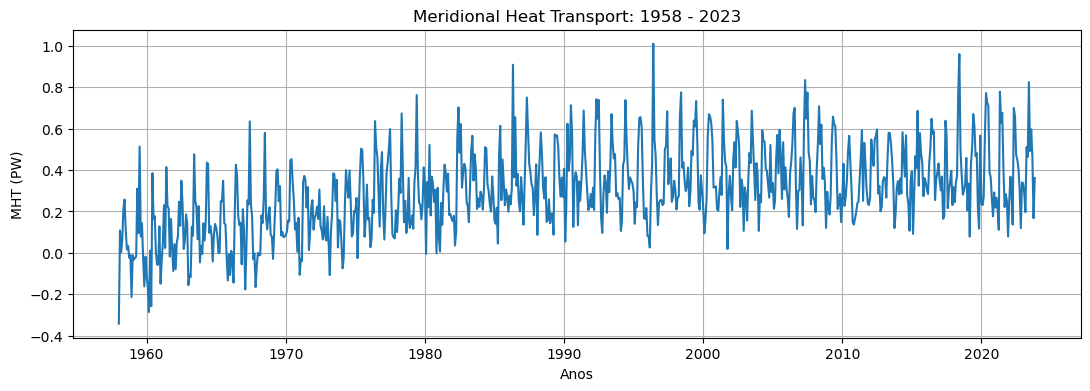

In [10]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_total_em_PW)
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: 1958 - 2023') #título
plt.grid(True)
plt.savefig('MHT_TOTAL')
plt.show()

In [41]:
prof

masked_array(data=[2.50000000e+00, 7.50000000e+00, 1.25000000e+01,
                   1.75000000e+01, 2.25000000e+01, 2.75000000e+01,
                   3.25000000e+01, 3.75000000e+01, 4.25000000e+01,
                   4.75000000e+01, 5.25000000e+01, 5.75000000e+01,
                   6.25000000e+01, 6.75000000e+01, 7.25000000e+01,
                   7.75000000e+01, 8.25000000e+01, 8.75000000e+01,
                   9.25000000e+01, 9.75000000e+01, 1.02500000e+02,
                   1.07523117e+02, 1.12615456e+02, 1.17822685e+02,
                   1.23189758e+02, 1.28760666e+02, 1.34578110e+02,
                   1.40683319e+02, 1.47115692e+02, 1.53912643e+02,
                   1.61109344e+02, 1.68738480e+02, 1.76830093e+02,
                   1.85411346e+02, 1.94506424e+02, 2.04136292e+02,
                   2.14318665e+02, 2.25067825e+02, 2.36394577e+02,
                   2.48306122e+02, 2.60806122e+02, 2.73894562e+02,
                   2.87567841e+02, 3.01818665e+02, 3.16636292e

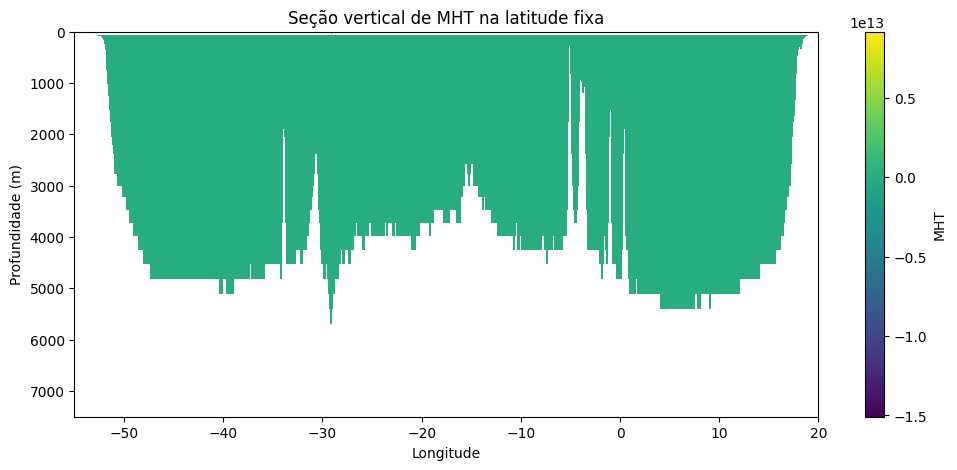

In [94]:
## este gráfico está errado porque rodei os dados de outra célula para testar as longitudes. Rodar sempre na ordem. 

plt.figure(figsize=(12, 5))

plt.pcolormesh(lon, prof, cumsum, shading='auto', cmap='viridis')

# plt.gca().invert_yaxis()      # profundidade aumenta para baixo
plt.colorbar(label='MHT') #coloca a escala do lado.

x_min = -55
x_max = 20
plt.xlim(x_min, x_max)

y_min = 0
y_max = 7500
plt.ylim(y_max, y_min)

plt.xlabel('Longitude') #eixo x 
plt.ylabel('Profundidade (m)') #eixo y
plt.title('Seção vertical de MHT na latitude fixa') #título
plt.show()

In [ ]:
Fazer um Hovmoller

# CÁLCULO DE ÉPOCAS

## MESES DO ANO

In [80]:
jan = []
fev = []
mar = []
apr = []
may = []
jun = []
jul = []
aug = []
sep = []
octo = []
nov = [] 
dez = []

for i in range(0, len(MHT_total_em_PW) - 11, 12):
    jan.append(MHT_total_em_PW[i])
    fev.append(MHT_total_em_PW[i+1])
    mar.append(MHT_total_em_PW[i+2])
    apr.append(MHT_total_em_PW[i+3])
    may.append(MHT_total_em_PW[i+4])
    jun.append(MHT_total_em_PW[i+5])
    jul.append(MHT_total_em_PW[i+6])
    aug.append(MHT_total_em_PW[i+7])
    sep.append(MHT_total_em_PW[i+8])
    octo.append(MHT_total_em_PW[i+9])
    nov.append(MHT_total_em_PW[i+10])
    dez.append(MHT_total_em_PW[i+11])

NameError: name 'MHT_superficie_em_PW' is not defined

In [39]:
meses_dados = [jan, fev, mar, apr, may, jun, jul, aug, sep, octo, nov, dez]
medias = [np.mean(m) for m in meses_dados]

In [50]:
medias

[np.float32(0.18269986),
 np.float32(0.16008939),
 np.float32(0.17921185),
 np.float32(0.29702675),
 np.float32(0.45297423),
 np.float32(0.5344404),
 np.float32(0.45750225),
 np.float32(0.37451956),
 np.float32(0.25843486),
 np.float32(0.2000125),
 np.float32(0.20768335),
 np.float32(0.2418493)]

In [55]:
serie_toda = []

In [58]:
serie_toda = medias * 66

In [60]:
serie_toda.pop()

np.float32(0.2418493)

In [61]:
len(serie_toda)

791

In [54]:
len(MHT_total_em_PW)

791

In [53]:
len(serie_toda)

9492

## MÉDIA ANUAL

In [33]:
media = []
anos = []

for i in range(0, len(MHT_total_em_PW), 12):
    means = np.mean(MHT_total_em_PW[i:i+12])
    media.append(means)

In [34]:
len(media)

66

In [35]:
for i in range (2023- 1957):
    yr = 1958 + i
    anos.append(yr)

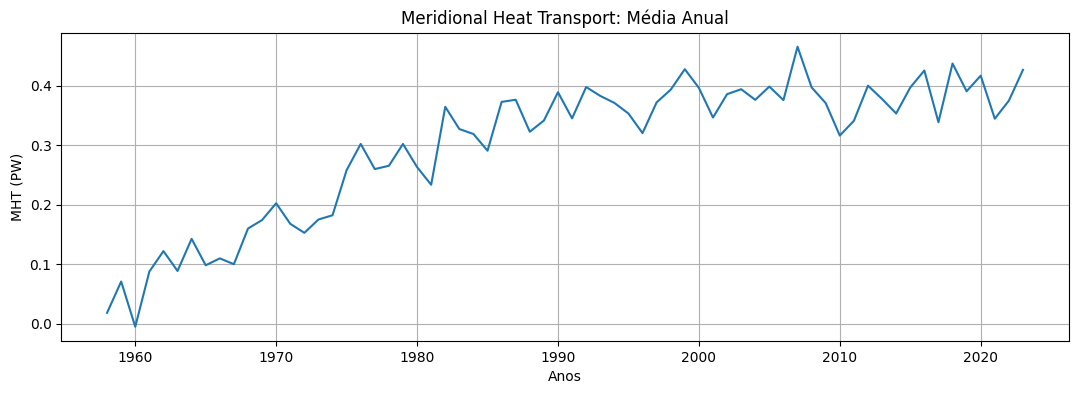

In [96]:
plt.figure(figsize=(13, 4))
plt.plot(anos,media)
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: Média Anual') #título
plt.grid(True)
plt.savefig('MHT_Médias_Anuais')
plt.show()

## ESTAÇÕES DO ANO

### VERÃO

In [37]:
# CONSIDERANDO DJF 

veroes = []

for i in range(1):
        means_veroes = np.mean(MHT_total_em_PW[i:i+2])
        veroes.append(means_veroes)

for i in range (11, len(MHT_total), 12):
        means_veroes = np.mean(MHT_total_em_PW[i:i+3])
        veroes.append(means_veroes) 

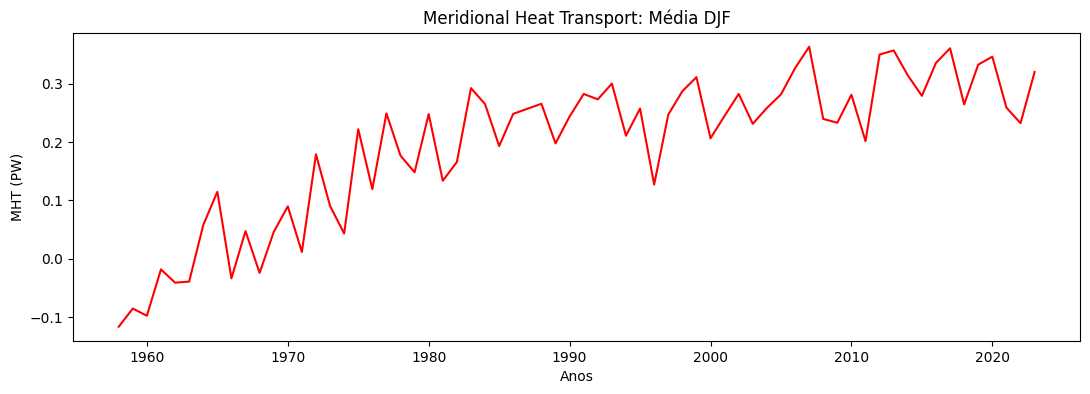

In [38]:
plt.figure(figsize=(13, 4))
plt.plot(anos,veroes, color = 'red')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: Média DJF') #título
plt.savefig('MHT_Médias_DJF')
plt.show()

### OUTONO

In [39]:
# CONSIDERANDO MAM

outonos = []

for i in range (2, len(MHT_total_em_PW), 12):
        means_outonos = np.mean(MHT_total_em_PW[i:i+3])
        outonos.append(means_outonos) 

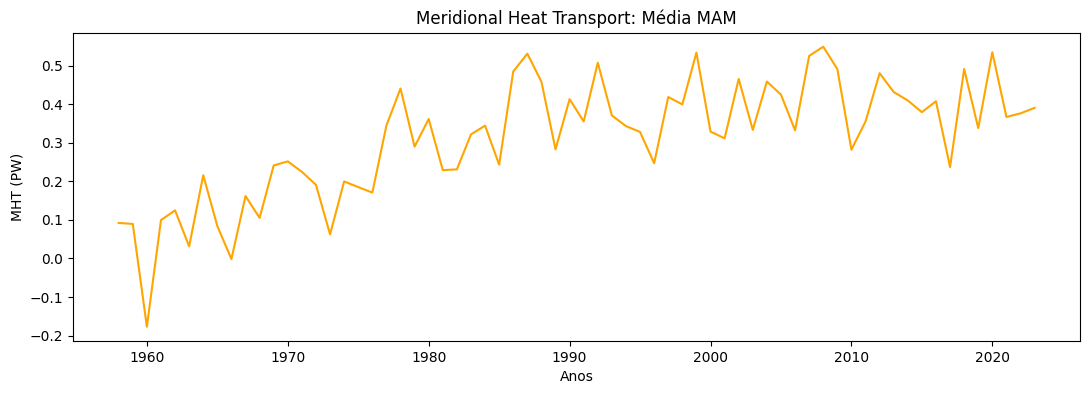

In [40]:
plt.figure(figsize=(13, 4))
plt.plot(anos,outonos, color = 'orange')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: Média MAM') #título
plt.savefig('MHT_Médias_MAM')
plt.show()

### INVERNO

In [41]:
# CONSIDERANDO JJA

inverno = []

for i in range (5, len(MHT_total_em_PW), 12):
        means_inverno = np.mean(MHT_total_em_PW[i:i+3])
        inverno.append(means_inverno) 

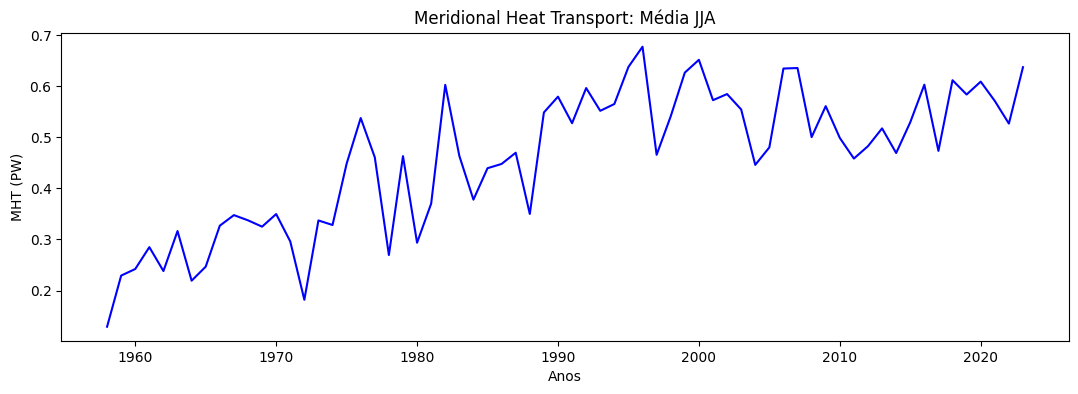

In [42]:
plt.figure(figsize=(13, 4))
plt.plot(anos,inverno, color = 'blue')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: Média JJA') #título
plt.savefig('MHT_Médias_JJA')
plt.show()

### PRIMAVERA

In [43]:
# CONSIDERANDO SON

prima = []

for i in range (8, len(MHT_total_em_PW), 12):
        means_prima = np.mean(MHT_total_em_PW[i:i+3])
        prima.append(means_prima) 

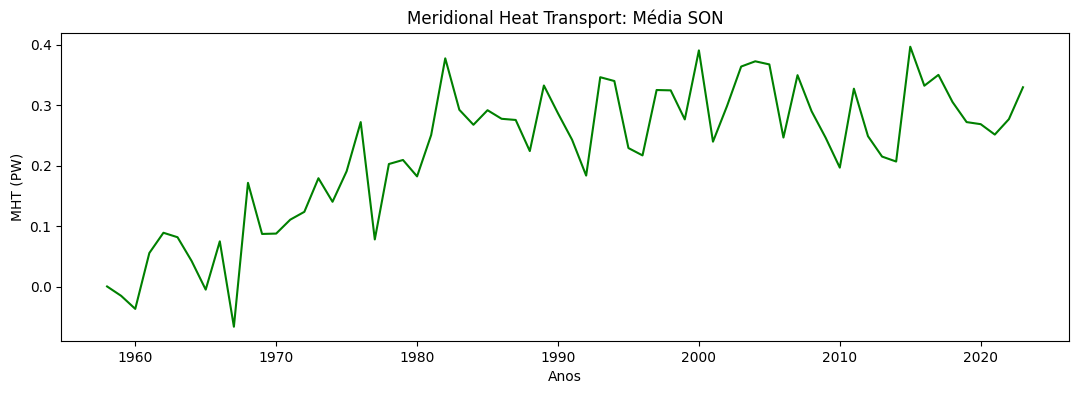

In [44]:
plt.figure(figsize=(13, 4))
plt.plot(anos,prima, color = 'green')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: Média SON') #título
plt.savefig('MHT_Médias_SON')
plt.show()

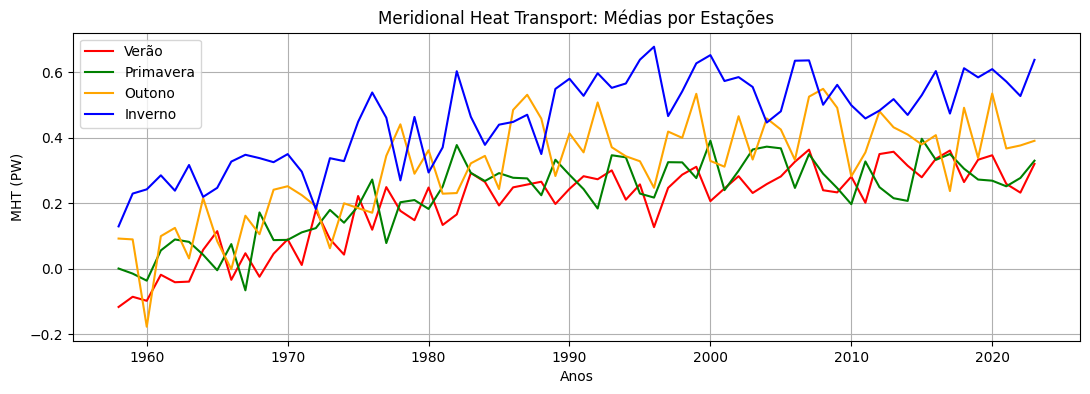

In [97]:
plt.figure(figsize=(13, 4))
plt.plot(anos, veroes, label="Verão", color = 'red')
plt.plot(anos,prima, label="Primavera", color = 'green')
plt.plot(anos, outonos, label="Outono", color = 'orange')
plt.plot(anos, inverno, label="Inverno", color = 'blue')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.legend()
plt.title('Meridional Heat Transport: Médias por Estações') #título
plt.grid(True)
plt.savefig('MHT_Médias_Seasons')
plt.show()

In [46]:
anos_sazonais = []

for i in range(len(veroes)):
    anos_sazonais.append([anos[i], veroes[i],outonos[i],inverno[i],prima[i]])


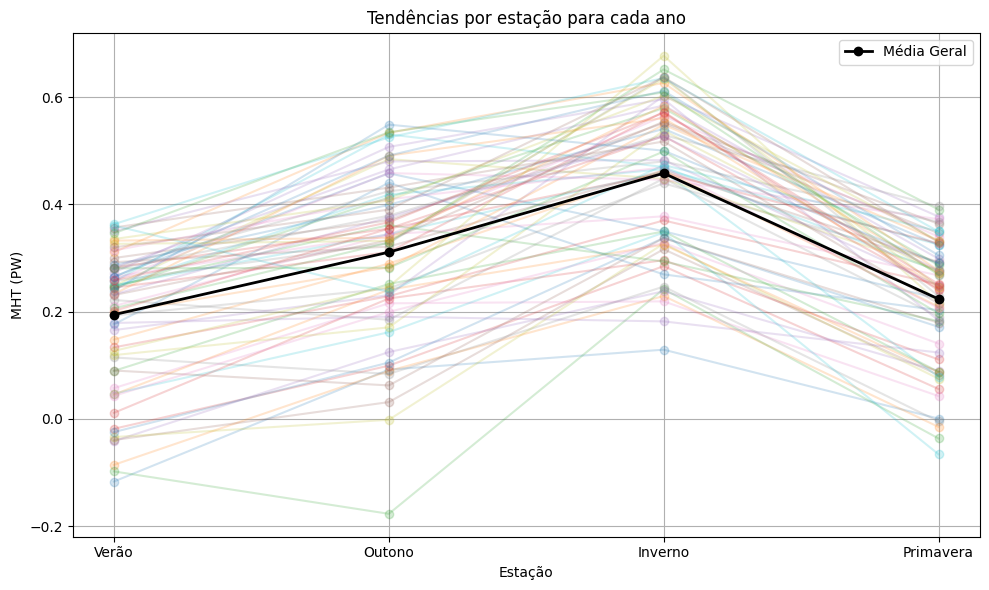

In [47]:
estacoes = ['Verão', 'Outono', 'Inverno', 'Primavera']
x = range(len(estacoes))  # [0,1,2,3]

plt.figure(figsize=(10,6))

media_geral_verao = np.mean(veroes)
media_geral_inverno = np.mean(inverno)
media_geral_outono = np.mean(outonos)
media_geral_prima = np.mean(prima)

# plotar cada ano como uma linha
for linha in anos_sazonais:
    ano = linha[0]
    valores = linha[1:]  # verão, outono, inverno, primavera
    plt.plot(x, valores, marker='o', alpha=0.2)

medias_todas = [media_geral_verao, media_geral_outono, media_geral_inverno, media_geral_prima]
plt.plot(x, medias_todas, marker='o', color='black', linewidth=2, label='Média Geral')

plt.xticks(x, estacoes)
plt.xlabel('Estação')
plt.ylabel('MHT (PW)')
plt.title('Tendências por estação para cada ano')
plt.grid(True)
plt.legend()
plt.savefig('Tendências por estação')
plt.tight_layout()
plt.show()

# SEPARAÇÃO POR CAMADAS 

In [14]:
from netCDF4 import Dataset

In [19]:
v_datasets[k].variables['v']

<class 'netCDF4._netCDF4.Variable'>
float32 v(lev, lon)
    _FillValue: -1e+34
    long_name: [cm/s] meridional velocity 
    coordinates: lat time
    missing_value: -1e+34
unlimited dimensions: 
current shape = (105, 901)
filling on

In [ ]:
float32 v(lev, lon)

In [25]:
v_datasets[k].variables['lon']

<class 'netCDF4.Variable'>
float64 lon(lon)
    _FillValue: nan
    grads_dim: x
    grads_mapping: linear
    grads_size: 3600
    units: degrees_east
    long_name: longitude
    minimum: 0.1
    maximum: 360.0
    resolution: 0.1
unlimited dimensions: 
current shape = (901,)
filling on

In [26]:
v_datasets[k].variables['lev']

<class 'netCDF4.Variable'>
float64 lev(lev)
    _FillValue: nan
    grads_dim: z
    grads_mapping: levels
    units: millibar
    long_name: altitude
    minimum: 2.5
    maximum: 7350.0
    resolution: 70.64904
unlimited dimensions: 
current shape = (105,)
filling on

In [27]:
v_datasets[k].variables['v']

<class 'netCDF4.Variable'>
float32 v(lev, lon)
    _FillValue: -1e+34
    long_name: [cm/s] meridional velocity 
    coordinates: lat time
    missing_value: -1e+34
unlimited dimensions: 
current shape = (105, 901)
filling on

### Descobrindo Profundidades

In [54]:
cp = 3990
ro = 1025
dx = 8700

ano = []

for k in range(791):
    lon  = v_datasets[k].variables['lon'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0
    prof = v_datasets[k].variables['lev'][:]

    mes = []

    for j in range(len(prof)):
        if j == 0:
            dz = prof[0]
        else:
            dz = prof[j] - prof[j-1]

        # soma ao longo de lon
        velocidade_prof = np.nansum(v[j, :] * dx * dz)

        mes.append(velocidade_prof)

    mes = np.cumsum(mes)
    ano.append(mes)
    print(f'data = {k}, = OK')

data = 0, = OK
data = 1, = OK
data = 2, = OK
data = 3, = OK
data = 4, = OK
data = 5, = OK
data = 6, = OK
data = 7, = OK
data = 8, = OK
data = 9, = OK
data = 10, = OK
data = 11, = OK
data = 12, = OK
data = 13, = OK
data = 14, = OK
data = 15, = OK
data = 16, = OK
data = 17, = OK
data = 18, = OK
data = 19, = OK
data = 20, = OK
data = 21, = OK
data = 22, = OK
data = 23, = OK
data = 24, = OK
data = 25, = OK
data = 26, = OK
data = 27, = OK
data = 28, = OK
data = 29, = OK
data = 30, = OK
data = 31, = OK
data = 32, = OK
data = 33, = OK
data = 34, = OK
data = 35, = OK
data = 36, = OK
data = 37, = OK
data = 38, = OK
data = 39, = OK
data = 40, = OK
data = 41, = OK
data = 42, = OK
data = 43, = OK
data = 44, = OK
data = 45, = OK
data = 46, = OK
data = 47, = OK
data = 48, = OK
data = 49, = OK
data = 50, = OK
data = 51, = OK
data = 52, = OK
data = 53, = OK
data = 54, = OK
data = 55, = OK
data = 56, = OK
data = 57, = OK
data = 58, = OK
data = 59, = OK
data = 60, = OK
data = 61, = OK
data = 62, = OK
da

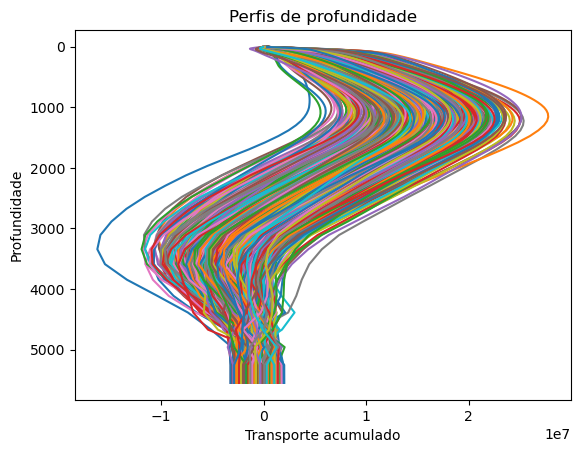

In [55]:
for i in range(len(ano)):
    plt.plot(ano[i], prof)

plt.gca().invert_yaxis()  # profundidade aumenta pra baixo
plt.xlabel('Transporte acumulado')
plt.ylabel('Profundidade')
plt.title('Perfis de profundidade')
plt.show()

In [56]:
MEDIA_PROFUNDIDADES = []

MEDIA_PROFUNDIDADES = np.mean(ano, axis=0)

In [64]:
idx_max = np.argmax(MEDIA_PROFUNDIDADES)
print(idx_max)

99


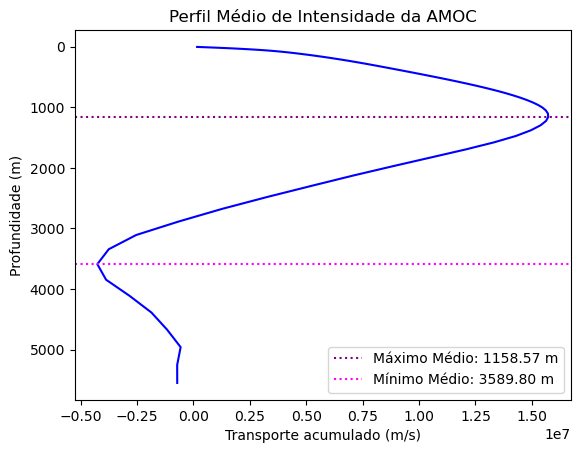

In [82]:
x = np.array(MEDIA_PROFUNDIDADES)
y = np.array(prof)

plt.plot(x, y, color = 'blue')

# Linha no máximo
idx_max = np.nanargmax(x)
plt.axhline(y=y[idx_max], color='purple', linestyle=':', label=f'Máximo Médio: {y[idx_max]:.2f} m')
idx_min = np.nanargmin(x)
plt.axhline(y=y[idx_min], color='magenta', linestyle=':', label=f'Mínimo Médio: {y[idx_min]:.2f} m')

plt.gca().invert_yaxis()  # profundidade aumenta pra baixo
plt.xlabel('Transporte acumulado (m/s)')
plt.ylabel('Profundidade (m)')
plt.title('Perfil Médio de Intensidade da AMOC')
plt.legend(loc='lower right')

plt.savefig('Perfil_Medio_Max_AMOC')

plt.show()

### Teste prof máximos e mínimos

In [77]:
valores_maximos_amoc = []
prof_dos_pontos_maximos = []

for i in range(len(intensidade_amoc)):
    valores_maximos_amoc.append(intensidade_amoc_max[i][0])
    prof_dos_pontos_maximos.append(intensidade_amoc_max[i][1])


In [84]:
valores_minimos_amoc = []
prof_dos_pontos_minimos = []

for i in range(len(intensidade_amoc_min)):
    valores_minimos_amoc.append(intensidade_amoc_min[i][0])
    prof_dos_pontos_minimos.append(intensidade_amoc_min[i][1])

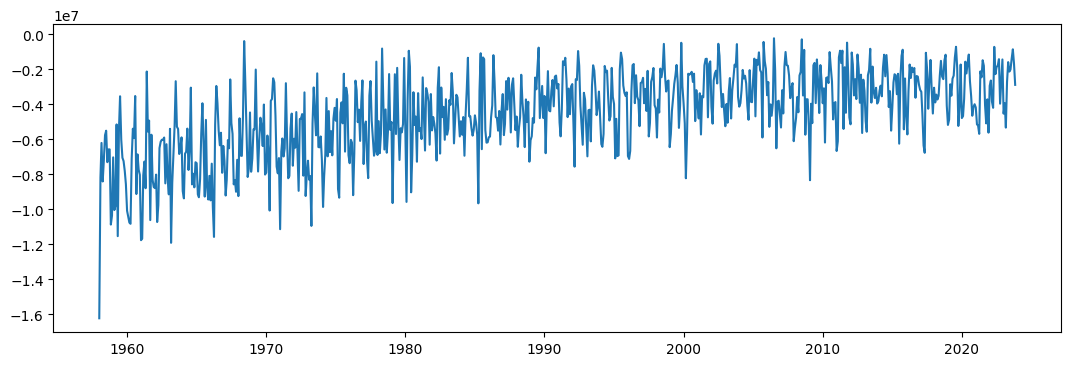

In [85]:
plt.figure(figsize=(13, 4))
plt.plot(t,valores_minimos_amoc)

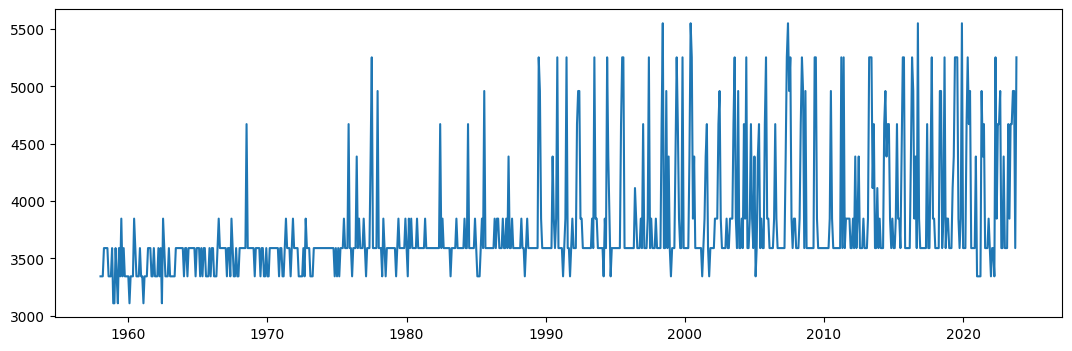

In [86]:
plt.figure(figsize=(13, 4))
plt.plot(t,prof_dos_pontos_mos)

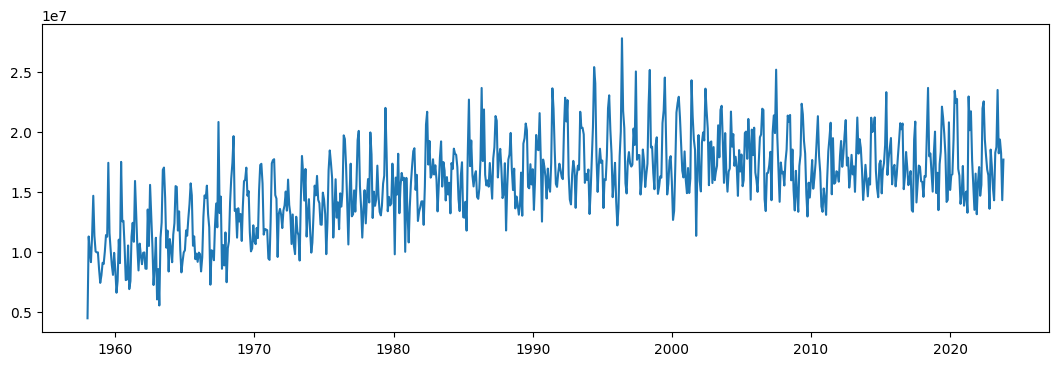

In [82]:
plt.figure(figsize=(13, 4))
plt.plot(t,valores_maximos_amoc)

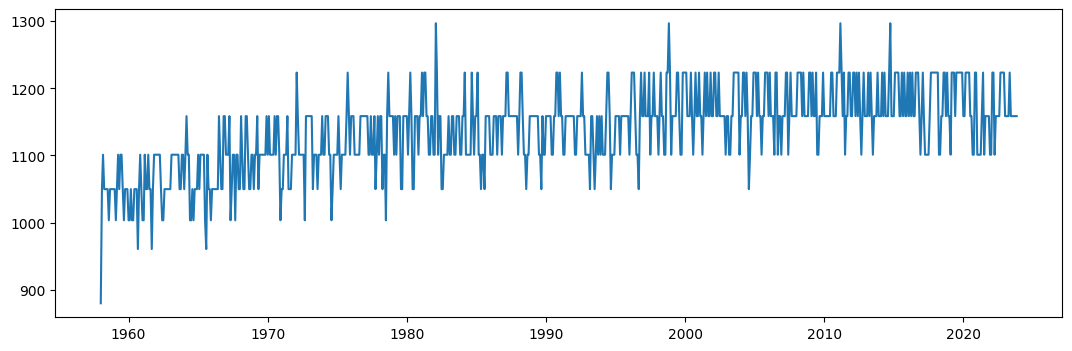

In [81]:
plt.figure(figsize=(13, 4))
plt.plot(t,prof_dos_pontos_maximos)

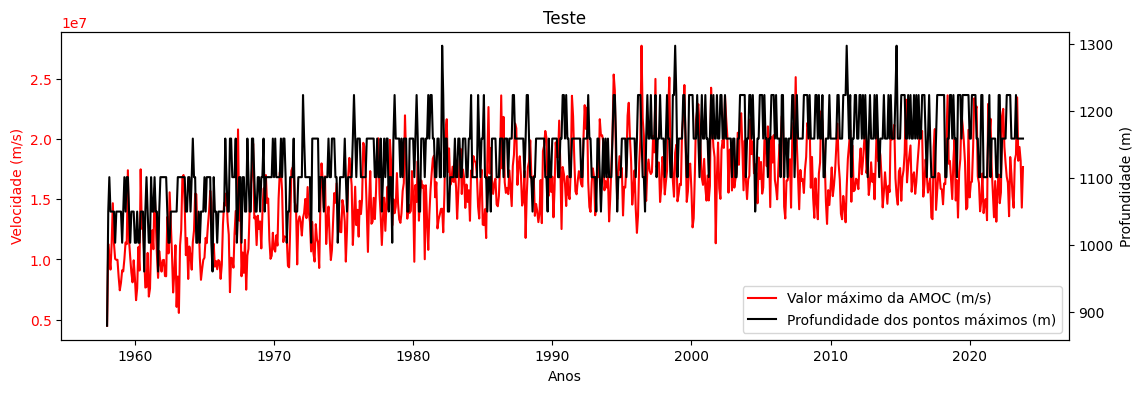

In [80]:
fig, ax1 = plt.subplots(figsize=(13, 4))

# Primeiro eixo y (esquerda)
ax1.plot(t, valores_maximos_amoc, color='red', label='Valor máximo da AMOC (m/s)')
ax1.set_xlabel('Anos')
ax1.set_ylabel('Velocidade (m/s)', color='red')
ax1.tick_params(axis='y', labelcolor='red')

# Segundo eixo y (direita)
ax2 = ax1.twinx()  # cria um segundo eixo y compartilhando o eixo x
ax2.plot(t, prof_dos_pontos_maximos, color='black', label='Profundidade dos pontos máximos (m)')
ax2.set_ylabel('Profundidade (m)', color='black')
ax2.tick_params(axis='y', labelcolor='black')

# Título
plt.title('Teste')

# Legenda combinada
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right')

plt.show()

### Profundidades de Interesse

#### Superfície

In [32]:
cp = 3990
ro = 1025
dx = 8700

MHT_superficie = []

for k in range(791):

    lon  = theta_datasets[k].variables['lon'][:]

    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0

    prof2 = theta_datasets[k].variables['lev'][:]
    prof2 = prof2[prof2 <= 1159]

    temp = temp[:len(prof2), :]
    v    = v[:len(prof2), :]

    # ajusta número de longitudes
    nlon = min(temp.shape[1], v.shape[1])

    temp = temp[:, :nlon]
    v    = v[:, :nlon]

    dz = np.diff(np.insert(prof2, 0, 0))

    cumsum = temp * v * cp * ro * dx * dz[:, np.newaxis]

    soma_atual = np.nansum(cumsum)

    print(f'soma do arquivo {k} = {soma_atual:.3e} W')

    MHT_superficie.append(soma_atual)

C:\Users\Rodrigo\anaconda3\Lib\site-packages\numpy\ma\core.py:1020: RuntimeWarning: overflow encountered in multiply
  result = self.f(da, db, *args, **kwargs)


soma do arquivo 0 = -5.900e+13 W
soma do arquivo 1 = 3.713e+14 W
soma do arquivo 2 = 2.245e+14 W
soma do arquivo 3 = 2.913e+14 W
soma do arquivo 4 = 4.484e+14 W
soma do arquivo 5 = 5.372e+14 W
soma do arquivo 6 = 3.534e+14 W
soma do arquivo 7 = 2.568e+14 W
soma do arquivo 8 = 2.636e+14 W
soma do arquivo 9 = 2.048e+14 W
soma do arquivo 10 = 2.389e+14 W
soma do arquivo 11 = 3.850e+13 W
soma do arquivo 12 = 2.044e+14 W
soma do arquivo 13 = 2.390e+14 W
soma do arquivo 14 = 2.241e+14 W
soma do arquivo 15 = 2.079e+14 W
soma do arquivo 16 = 5.810e+14 W
soma do arquivo 17 = 3.391e+14 W
soma do arquivo 18 = 8.016e+14 W
soma do arquivo 19 = 3.316e+14 W
soma do arquivo 20 = 3.917e+14 W
soma do arquivo 21 = 2.023e+14 W
soma do arquivo 22 = 8.284e+13 W
soma do arquivo 23 = 2.417e+14 W
soma do arquivo 24 = 1.533e+14 W
soma do arquivo 25 = 8.177e+13 W
soma do arquivo 26 = 1.998e+12 W
soma do arquivo 27 = 3.097e+14 W
soma do arquivo 28 = 2.909e+13 W
soma do arquivo 29 = 6.641e+14 W
soma do arquivo 30 

In [4]:
cp = 3990       # J/kg/K para água do mar
ro = 1025       # kg/m3
dx = 8700       # m
MHT_superficie = []

for k in range(791):
    lon  = theta_datasets[k].variables['lon'][:]
    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s
    prof2 = theta_datasets[k].variables['lev'][:]
    prof2 = prof2[prof2 <= 1159]

    cumsum = np.zeros_like(temp)

    for i in range(len(lon)):
        for j in range(len(prof2)):
            if j == 0:
                dz = prof2[0]
            else:
                dz = prof2[j] - prof2[j-1]

            cumsum[j][i] = temp[j][i] * v[j][i] * cp * ro * dx * dz

    soma_atual = np.nansum(cumsum)
    print(f'soma do arquivo {k} = {soma_atual:.3e} W')
    MHT_superficie.append(soma_atual)

soma do arquivo 0 = -5.900e+13 W
soma do arquivo 1 = 3.713e+14 W
soma do arquivo 2 = 2.245e+14 W
soma do arquivo 3 = 2.913e+14 W
soma do arquivo 4 = 4.484e+14 W
soma do arquivo 5 = 5.372e+14 W
soma do arquivo 6 = 3.534e+14 W
soma do arquivo 7 = 2.568e+14 W
soma do arquivo 8 = 2.636e+14 W
soma do arquivo 9 = 2.048e+14 W
soma do arquivo 10 = 2.389e+14 W
soma do arquivo 11 = 3.850e+13 W
soma do arquivo 12 = 2.044e+14 W
soma do arquivo 13 = 2.390e+14 W
soma do arquivo 14 = 2.241e+14 W


KeyboardInterrupt: 

In [48]:
len(prof3)

105

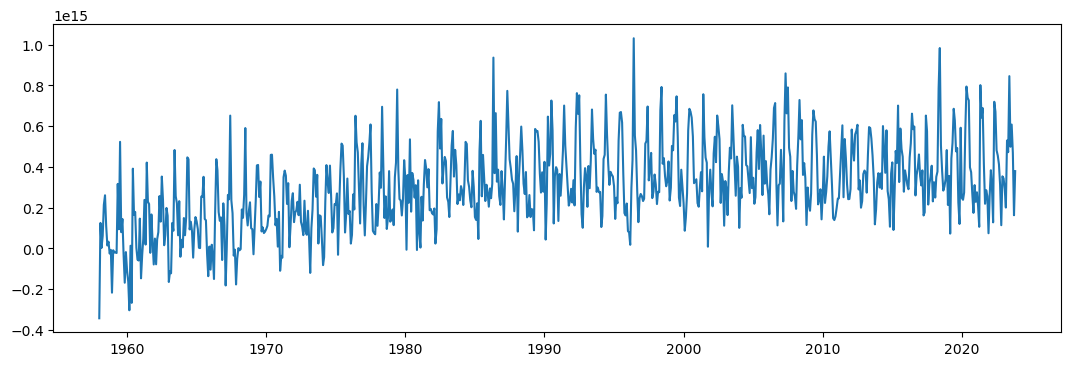

In [89]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_superficie)

In [44]:
prof3

masked_array(data=[2.50000000e+00, 7.50000000e+00, 1.25000000e+01,
                   1.75000000e+01, 2.25000000e+01, 2.75000000e+01,
                   3.25000000e+01, 3.75000000e+01, 4.25000000e+01,
                   4.75000000e+01, 5.25000000e+01, 5.75000000e+01,
                   6.25000000e+01, 6.75000000e+01, 7.25000000e+01,
                   7.75000000e+01, 8.25000000e+01, 8.75000000e+01,
                   9.25000000e+01, 9.75000000e+01, 1.02500000e+02,
                   1.07523117e+02, 1.12615456e+02, 1.17822685e+02,
                   1.23189758e+02, 1.28760666e+02, 1.34578110e+02,
                   1.40683319e+02, 1.47115692e+02, 1.53912643e+02,
                   1.61109344e+02, 1.68738480e+02, 1.76830093e+02,
                   1.85411346e+02, 1.94506424e+02, 2.04136292e+02,
                   2.14318665e+02, 2.25067825e+02, 2.36394577e+02,
                   2.48306122e+02, 2.60806122e+02, 2.73894562e+02,
                   2.87567841e+02, 3.01818665e+02, 3.16636292e

In [11]:
valor = 1159
idx = np.abs(prof2 - valor).argmin()
print(idx)

75


#### NADW

In [57]:
valor = 1158 
idx = np.abs(prof - valor).argmin()
print(idx)

75


In [54]:
prof

masked_array(data=[2.50000000e+00, 7.50000000e+00, 1.25000000e+01,
                   1.75000000e+01, 2.25000000e+01, 2.75000000e+01,
                   3.25000000e+01, 3.75000000e+01, 4.25000000e+01,
                   4.75000000e+01, 5.25000000e+01, 5.75000000e+01,
                   6.25000000e+01, 6.75000000e+01, 7.25000000e+01,
                   7.75000000e+01, 8.25000000e+01, 8.75000000e+01,
                   9.25000000e+01, 9.75000000e+01, 1.02500000e+02,
                   1.07523117e+02, 1.12615456e+02, 1.17822685e+02,
                   1.23189758e+02, 1.28760666e+02, 1.34578110e+02,
                   1.40683319e+02, 1.47115692e+02, 1.53912643e+02,
                   1.61109344e+02, 1.68738480e+02, 1.76830093e+02,
                   1.85411346e+02, 1.94506424e+02, 2.04136292e+02,
                   2.14318665e+02, 2.25067825e+02, 2.36394577e+02,
                   2.48306122e+02, 2.60806122e+02, 2.73894562e+02,
                   2.87567841e+02, 3.01818665e+02, 3.16636292e

In [33]:
ro = 1025
cp = 3990
dx = 8700

MHT_transição = []

for k in range(791):

    lon  = theta_datasets[k].variables['lon'][:]

    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0

    prof3 = theta_datasets[k].variables['lev'][:]

    # seleciona faixa de profundidade
    mask = (prof3 >= 1159) & (prof3 <= 3590)

    temp_sel = temp[mask, :]
    v_sel    = v[mask, :]
    prof_sel = prof3[mask]

    # corrige diferença de longitude
    nlon = min(temp_sel.shape[1], v_sel.shape[1])

    temp_sel = temp_sel[:, :nlon]
    v_sel    = v_sel[:, :nlon]

    # calcula dz
    dz = np.empty(len(prof_sel))

    dz[0] = prof_sel[1] - prof_sel[0]
    dz[1:] = np.diff(prof_sel)

    # cálculo vetorizado
    cumsum = temp_sel * v_sel * cp * ro * dx * dz[:, np.newaxis]

    soma_atual = np.nansum(cumsum)

    print(f'soma do arquivo {k} = {soma_atual:.3e} W')

    MHT_transição.append(soma_atual)

soma do arquivo 0 = -2.967e+14 W
soma do arquivo 1 = -2.684e+14 W
soma do arquivo 2 = -2.251e+14 W
soma do arquivo 3 = -2.334e+14 W
soma do arquivo 4 = -2.450e+14 W
soma do arquivo 5 = -2.736e+14 W
soma do arquivo 6 = -2.353e+14 W
soma do arquivo 7 = -2.442e+14 W
soma do arquivo 8 = -2.262e+14 W
soma do arquivo 9 = -2.239e+14 W
soma do arquivo 10 = -2.624e+14 W
soma do arquivo 11 = -2.609e+14 W
soma do arquivo 12 = -2.188e+14 W
soma do arquivo 13 = -2.777e+14 W
soma do arquivo 14 = -2.483e+14 W
soma do arquivo 15 = -2.212e+14 W
soma do arquivo 16 = -2.803e+14 W
soma do arquivo 17 = -2.318e+14 W
soma do arquivo 18 = -2.750e+14 W
soma do arquivo 19 = -2.525e+14 W
soma do arquivo 20 = -2.480e+14 W
soma do arquivo 21 = -2.293e+14 W
soma do arquivo 22 = -2.472e+14 W
soma do arquivo 23 = -2.618e+14 W
soma do arquivo 24 = -2.639e+14 W
soma do arquivo 25 = -2.512e+14 W
soma do arquivo 26 = -2.978e+14 W
soma do arquivo 27 = -3.064e+14 W
soma do arquivo 28 = -2.776e+14 W
soma do arquivo 29 = -2.

In [19]:
ro = 1025
dx = 8700
MHT_transição = []

for k in range(791):
    lon  = theta_datasets[k].variables['lon'][:]
    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0
    prof3 = theta_datasets[k].variables['lev'][:]

    mask = (prof3 >= 1159) & (prof3 <= 3590)

    temp_sel = temp[mask, :]
    v_sel    = v[mask, :]
    prof_sel = prof3[mask]

    cumsum = np.zeros_like(temp_sel)

    for i in range(len(lon)):
        for j in range(len(prof_sel)):
            if j == 0:
                dz = prof_sel[1] - prof_sel[0]
            else:
                dz = prof_sel[j] - prof_sel[j-1]

            cumsum[j][i] = temp_sel[j][i] * v_sel[j][i] * cp * ro * dx * dz

    soma_atual = np.nansum(cumsum)
    print(f'soma do arquivo {k} = {soma_atual:.3e} W')
    MHT_transição.append(soma_atual)

soma do arquivo 0 = -2.967e+14 W
soma do arquivo 1 = -2.684e+14 W
soma do arquivo 2 = -2.251e+14 W
soma do arquivo 3 = -2.334e+14 W
soma do arquivo 4 = -2.450e+14 W
soma do arquivo 5 = -2.736e+14 W
soma do arquivo 6 = -2.353e+14 W
soma do arquivo 7 = -2.442e+14 W
soma do arquivo 8 = -2.262e+14 W
soma do arquivo 9 = -2.239e+14 W
soma do arquivo 10 = -2.624e+14 W
soma do arquivo 11 = -2.609e+14 W
soma do arquivo 12 = -2.188e+14 W
soma do arquivo 13 = -2.777e+14 W
soma do arquivo 14 = -2.483e+14 W
soma do arquivo 15 = -2.212e+14 W
soma do arquivo 16 = -2.803e+14 W
soma do arquivo 17 = -2.318e+14 W
soma do arquivo 18 = -2.750e+14 W
soma do arquivo 19 = -2.525e+14 W
soma do arquivo 20 = -2.480e+14 W
soma do arquivo 21 = -2.293e+14 W
soma do arquivo 22 = -2.472e+14 W
soma do arquivo 23 = -2.618e+14 W
soma do arquivo 24 = -2.639e+14 W
soma do arquivo 25 = -2.512e+14 W
soma do arquivo 26 = -2.978e+14 W
soma do arquivo 27 = -3.064e+14 W
soma do arquivo 28 = -2.776e+14 W
soma do arquivo 29 = -2.

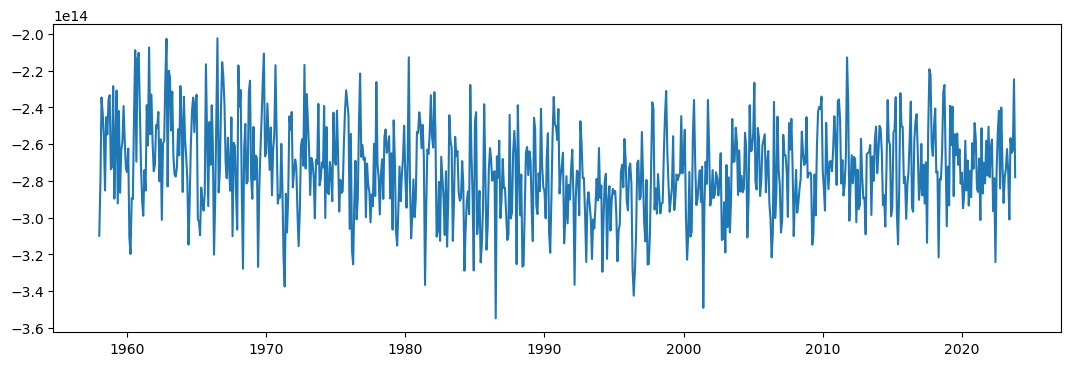

In [91]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_transição)

#### Fundo

In [60]:
valor = 3590 
idx = np.abs(prof - valor).argmin()
print(idx)

91


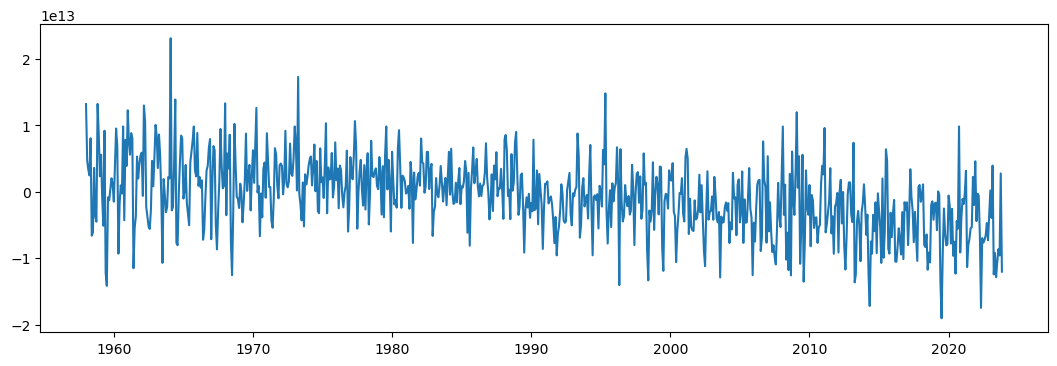

In [94]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_bottom)

In [34]:
ro = 1025       # kg/m3
cp = 3990       # J/kg/K
dx = 8700       # m

MHT_BOTTOM = []

for k in range(791):

    lon  = theta_datasets[k].variables['lon'][:]

    temp = theta_datasets[k].variables['temp'][:]

    v = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s

    prof5 = theta_datasets[k].variables['lev'][:]

    # profundidades >= 3590 m
    prof_BOTTOM = prof5[(prof5 >= 3590)]

    # mantém o mesmo offset do código original
    temp_sel = temp[91:91+len(prof_BOTTOM), :]
    v_sel    = v[91:91+len(prof_BOTTOM), :]

    # corrige possível diferença de longitude
    nlon = min(temp_sel.shape[1], v_sel.shape[1])

    temp_sel = temp_sel[:, :nlon]
    v_sel    = v_sel[:, :nlon]

    # calcula dz
    dz = np.empty(len(prof_BOTTOM))

    dz[0] = prof_BOTTOM[0]
    dz[1:] = np.diff(prof_BOTTOM)

    # cálculo vetorizado
    cumsum = temp_sel * v_sel * cp * ro * dx * dz[:, np.newaxis]

    soma_atual = np.nansum(cumsum)

    print(f'soma do arquivo {k} = {soma_atual:.3e} W')

    MHT_BOTTOM.append(soma_atual)

soma do arquivo 0 = -1.261e+13 W
soma do arquivo 1 = -7.000e+13 W
soma do arquivo 2 = -1.014e+14 W
soma do arquivo 3 = -1.052e+14 W
soma do arquivo 4 = -9.274e+13 W
soma do arquivo 5 = -1.512e+14 W
soma do arquivo 6 = -1.523e+14 W
soma do arquivo 7 = -8.666e+13 W
soma do arquivo 8 = -9.391e+13 W
soma do arquivo 9 = -1.002e+14 W
soma do arquivo 10 = -6.782e+13 W
soma do arquivo 11 = -6.392e+11 W
soma do arquivo 12 = -8.042e+13 W
soma do arquivo 13 = -7.840e+13 W
soma do arquivo 14 = -7.074e+13 W
soma do arquivo 15 = -7.201e+13 W
soma do arquivo 16 = -8.013e+13 W
soma do arquivo 17 = -8.189e+13 W
soma do arquivo 18 = -1.541e+14 W
soma do arquivo 19 = -7.389e+13 W
soma do arquivo 20 = -7.787e+13 W
soma do arquivo 21 = -4.979e+13 W
soma do arquivo 22 = -7.122e+13 W
soma do arquivo 23 = -8.711e+13 W
soma do arquivo 24 = -9.331e+13 W
soma do arquivo 25 = -5.191e+13 W
soma do arquivo 26 = -5.835e+13 W
soma do arquivo 27 = -7.793e+13 W
soma do arquivo 28 = -1.450e+14 W
soma do arquivo 29 = -1.

In [10]:
ro = 1025       # kg/m3
dx = 8700       # m
MHT_BOTTOM = []

for k in range(791):
    lon  = theta_datasets[k].variables['lon'][:]
    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s
    prof5 = theta_datasets[k].variables['lev'][:]
    prof_BOTTOM = prof5[(prof5 >= 3590)]

    cumsum = np.zeros_like(temp)

    for i in range(len(lon)):
        for j in range(len(prof_BOTTOM)):
            if j == 0:
                dz = prof_BOTTOM[0]
            else:
                dz = prof_BOTTOM[j] - prof_BOTTOM[j-1]

            cumsum[j][i] = temp[j+91][i] * v[j+91][i] * cp * ro * dx * dz

    soma_atual = np.nansum(cumsum)
    print(f'soma do arquivo {k} = {soma_atual:.3e} W')
    MHT_BOTTOM.append(soma_atual)


soma do arquivo 0 = -1.261e+13 W
soma do arquivo 1 = -7.000e+13 W
soma do arquivo 2 = -1.014e+14 W
soma do arquivo 3 = -1.052e+14 W
soma do arquivo 4 = -9.274e+13 W
soma do arquivo 5 = -1.512e+14 W
soma do arquivo 6 = -1.523e+14 W
soma do arquivo 7 = -8.666e+13 W
soma do arquivo 8 = -9.391e+13 W
soma do arquivo 9 = -1.002e+14 W
soma do arquivo 10 = -6.782e+13 W
soma do arquivo 11 = -6.393e+11 W
soma do arquivo 12 = -8.042e+13 W
soma do arquivo 13 = -7.840e+13 W


KeyboardInterrupt: 

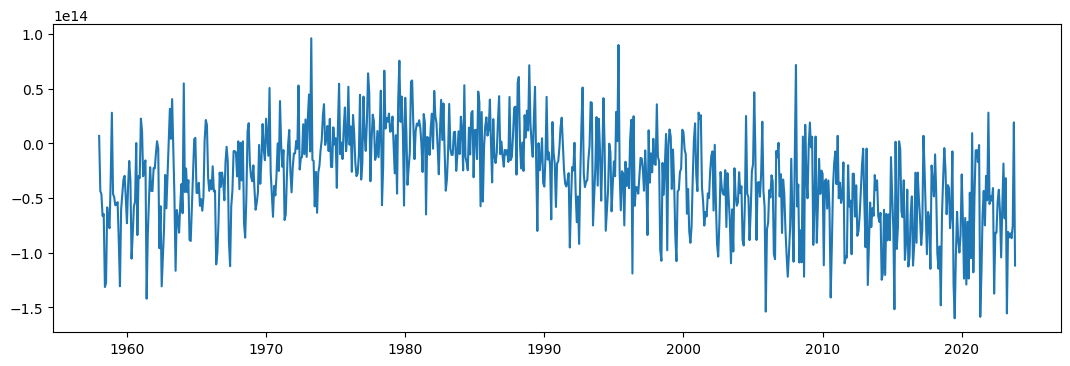

In [79]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_BOTTOM)

### Contribuição por camada

In [35]:
MHT_superficie_PW = []
MHT_transição_PW = []
MHT_BOTTOM_PW = []

for i in range (len(MHT_superficie)):
    MHT_superficie_PW.append(MHT_superficie[i] / (10**15))

In [36]:
for i in range (len(MHT_bottom)):
    MHT_BOTTOM_PW.append(MHT_bottom[i] / (10**15))

In [37]:
for i in range (len(MHT_transição)):
    MHT_transição_PW.append(MHT_transição[i] / (10**15))

In [38]:
import pandas as pd

df10 = pd.DataFrame({
    'data': t,          # sua lista de datetime
    'MHT_SUP': MHT_superficie_PW   # sua lista de MHT
})

df10['data'] = pd.to_datetime(df10['data'])

In [39]:
df10['decada'] = (df10['data'].dt.year // 10) * 10

In [40]:
media_decada = df10.groupby('decada')['MHT_SUP'].mean()
print(media_decada)

decada
1950    0.292374
1960    0.356863
1970    0.485884
1980    0.588744
1990    0.649876
2000    0.659469
2010    0.640777
2020    0.656489
Name: MHT_SUP, dtype: float64


In [26]:
import pandas as pd

df5 = pd.DataFrame({
    'data': t,          # sua lista de datetime
    'MHT_TRANS': MHT_transição_PW   # sua lista de MHT
})

df5['data'] = pd.to_datetime(df5['data'])

In [27]:
df5['decada'] = (df5['data'].dt.year // 10) * 10

In [28]:
media_decada = df5.groupby('decada')['MHT_TRANS'].mean()
print(media_decada)

decada
1950   -0.249457
1960   -0.251672
1970   -0.261694
1980   -0.269088
1990   -0.273816
2000   -0.266523
2010   -0.258936
2020   -0.261925
Name: MHT_TRANS, dtype: float64


In [29]:
import pandas as pd

df6 = pd.DataFrame({
    'data': t,          # sua lista de datetime
    'MHT_FUNDO': MHT_BOTTOM_PW   # sua lista de MHT
})

df6['data'] = pd.to_datetime(df6['data'])

In [30]:
df6['decada'] = (df6['data'].dt.year // 10) * 10

In [31]:
media_decada = df6.groupby('decada')['MHT_FUNDO'].mean()
print(media_decada)

decada
1950    0.000910
1960    0.001910
1970    0.002166
1980    0.001120
1990   -0.001190
2000   -0.002602
2010   -0.004428
2020   -0.004999
Name: MHT_FUNDO, dtype: float64


In [42]:
mean_sup_bruto = np.mean(MHT_superficie_PW)
mean_nadw_bruto = np.nanmean(MHT_transição_PW)
mean_fundo_bruto = np.nanmean(MHT_BOTTOM_PW)

In [43]:
print(mean_sup_bruto)
print(mean_nadw_bruto)
print(mean_fundo_bruto)

0.5608919502505433
-0.26309098592231545
-0.0007281144687544394


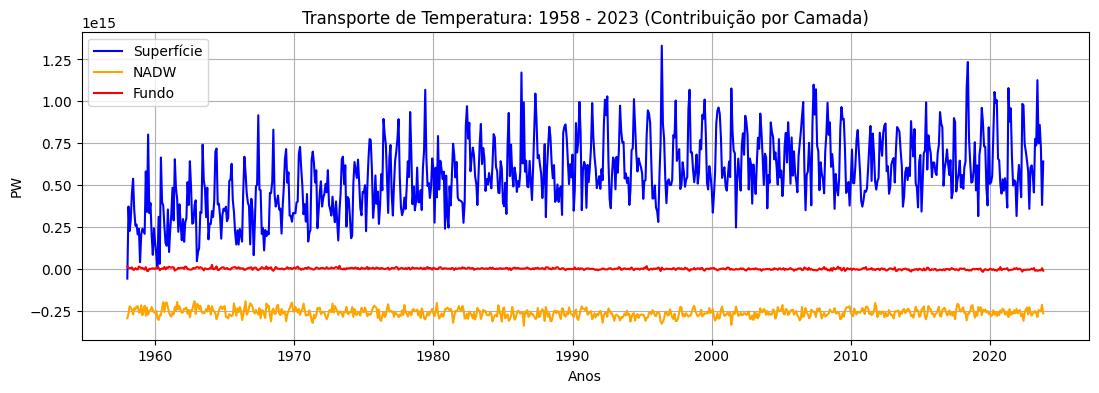

In [44]:
plt.figure(figsize=(13, 4))
plt.plot(t, MHT_superficie, label = 'Superfície',  color='blue')
plt.plot(t, MHT_transição, label = 'NADW' , color='orange')
plt.plot(t, MHT_bottom, label = 'Fundo', color='red')
plt.xlabel('Anos') #eixo x 
plt.ylabel('PW') #eixo y
plt.title('Transporte de Temperatura: 1958 - 2023 (Contribuição por Camada)') #título
plt.grid(True)
plt.legend(loc = 'upper left')
plt.savefig('MHT_Comparativo_Camadas_Temp')
plt.show()

In [44]:
sup_contrib = []
mid_contrib = []
fun_contrib = []

for i in range(len(MHT_superficie_PW)):

    total_abs = (
        abs(MHT_superficie_PW[i]) +
        abs(MHT_transição_PW[i]) +
        abs(MHT_BOTTOM_PW[i])
    )

    if total_abs != 0:
        sup_contrib.append(100 * abs(MHT_superficie_PW[i]) / total_abs)
        mid_contrib.append(100 * abs(MHT_transição_PW[i]) / total_abs)
        fun_contrib.append(100 * abs(MHT_BOTTOM_PW[i]) / total_abs)
    else:
        sup_contrib.append(np.nan)
        mid_contrib.append(np.nan)
        fun_contrib.append(np.nan)

In [47]:
mean_sup = np.mean(sup_contrib)
mean_mid = np.mean(mid_contrib)
mean_fun = np.mean(fun_contrib)

In [49]:
print(mean_sup)
print(mean_mid)
print(mean_fun)

65.39905
34.042168
0.5587887


# DIVIDINDO POR MARGEM 

### Dividindo as margens

In [9]:
cp = 3990       # J/kg/K para água do mar
ro = 1025       # kg/m3
dx = 8700       # m
ano = []
for k in range(791):
    lon  = theta_datasets[k].variables['lon'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s
    prof = theta_datasets[k].variables['lev'][:]
    mes = []

    for i in range(len(lon)):
        vsum = []
        for j in range(len(prof)):
            if j == 0:
                dz = prof[0]
            else:
                dz = prof[j] - prof[j-1]

            vsum.append(v[j][i] * dx * dz)
            
        velocidade_longitude = np.nansum(vsum)
        mes.append(velocidade_longitude)

    ano.append(mes)
    print(f'data = {k}, = OK')

data = 0, = OK
data = 1, = OK
data = 2, = OK
data = 3, = OK
data = 4, = OK
data = 5, = OK
data = 6, = OK
data = 7, = OK
data = 8, = OK
data = 9, = OK
data = 10, = OK
data = 11, = OK
data = 12, = OK
data = 13, = OK
data = 14, = OK
data = 15, = OK
data = 16, = OK
data = 17, = OK
data = 18, = OK
data = 19, = OK
data = 20, = OK
data = 21, = OK
data = 22, = OK
data = 23, = OK
data = 24, = OK
data = 25, = OK
data = 26, = OK
data = 27, = OK
data = 28, = OK
data = 29, = OK
data = 30, = OK
data = 31, = OK
data = 32, = OK
data = 33, = OK
data = 34, = OK
data = 35, = OK
data = 36, = OK
data = 37, = OK
data = 38, = OK
data = 39, = OK
data = 40, = OK
data = 41, = OK
data = 42, = OK
data = 43, = OK
data = 44, = OK
data = 45, = OK
data = 46, = OK
data = 47, = OK
data = 48, = OK
data = 49, = OK
data = 50, = OK
data = 51, = OK
data = 52, = OK
data = 53, = OK
data = 54, = OK
data = 55, = OK
data = 56, = OK
data = 57, = OK
data = 58, = OK
data = 59, = OK
data = 60, = OK
data = 61, = OK
data = 62, = OK
da

In [10]:
MEDIA_LONGITUDES = []

for i in range (len(ano)):
    for j in range (len(lon)):
        MEDIA_LONGITUDES.append = np.mean(ano[i])

[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000

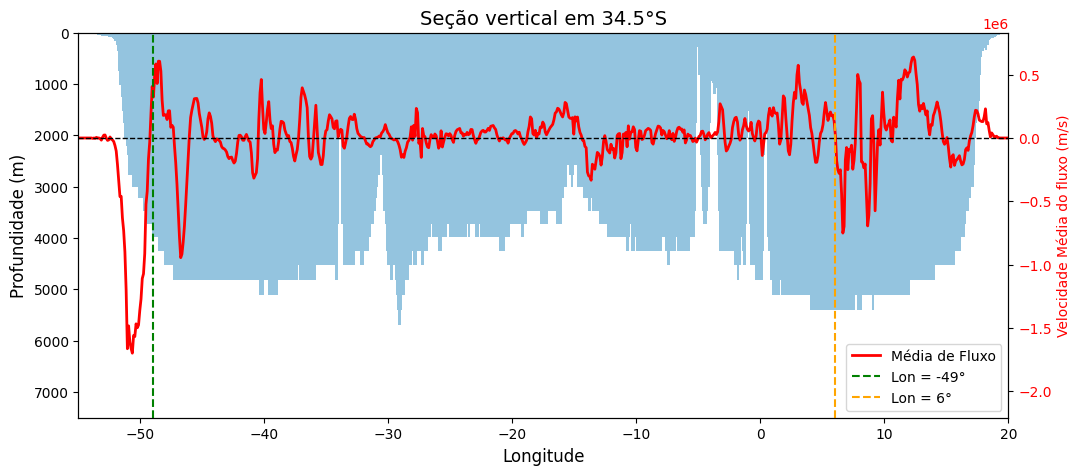

In [50]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize


# Cria fundo da bacia com valor constante 1 para azul intenso
cumsum = np.ones_like(temp)  # agora todo valor = 1 

plt.figure(figsize=(12, 5))

# fundo azul uniforme (pode mudar cmap se quiser outro tom)
plt.pcolormesh(
    lon, prof, cumsum, shading='auto', cmap='Blues',
    norm=Normalize(vmin=0, vmax=2.5)  # força azul intenso
)

plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Profundidade (m)', fontsize=12)
plt.xlim(-55, 20)
plt.ylim(7500, 0)
plt.title('Seção vertical em 34.5°S', fontsize=14)

# cria eixo y secundário à direita para a linha de fluxo
ax2 = plt.gca().twinx()
ax2.plot(lon, MEDIA_LONGITUDES, color='red', linewidth=2, label='Média de Fluxo')

# linha horizontal no valor 0 de velocidade
ax2.axhline(0, color='black', linewidth=1, linestyle='--')

# ajusta o eixo y da velocidade para ficar mais "bonito"
vmin = np.min(MEDIA_LONGITUDES) - 0.3 * abs(np.min(MEDIA_LONGITUDES))
vmax = np.max(MEDIA_LONGITUDES) + 0.3 * abs(np.max(MEDIA_LONGITUDES))
ax2.set_ylim(vmin, vmax)

ax2.set_ylabel('Velocidade Média do fluxo (m/s)', fontsize=10, color='red')
ax2.tick_params(axis='y', labelcolor='red', labelsize=10)

# linha vertical em x = -48
plt.axvline(x=-49, color='green', linestyle='--', linewidth=1.5, label='Lon = -49°')

# linha vertical em x = 3
plt.axvline(x=6, color='orange', linestyle='--', linewidth=1.5, label='Lon = 6°')

# se quiser, atualiza a legenda para incluir essas linhas
plt.legend(loc='lower right')

plt.savefig("Fluxo na Bacia")

plt.show()

In [16]:
cp = 3990       # J/kg/K para água do mar
ro = 1025       # kg/m3
dx = 8700       # m

lon  = theta_datasets[200].variables['lon'][:]
temp = theta_datasets[200].variables['temp'][:]
v    = v_datasets[200].variables['v'][:] / 100.0  # cm/s -> m/s
prof = theta_datasets[200].variables['lev'][:]

cumsum = np.zeros_like(temp)

for i in range(len(lon)):
    for j in range(len(prof)):
        if j == 0:
            dz = prof[0]
        else:
            dz = prof[j] - prof[j-1]

        cumsum[j][i] = temp[j][i] * v[j][i] * cp * ro * dx * dz

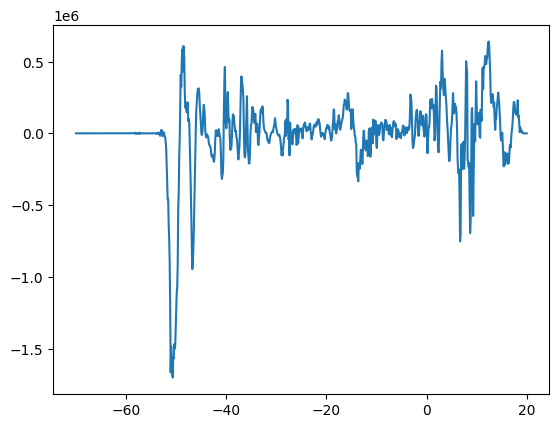

In [13]:
plt.plot(lon, MEDIA_LONGITUDES)

## MARGEM OESTE

In [54]:
cp = 3990       # J/kg/K
ro = 1025       # kg/m3
dx = 8700       # m

MHT_OESTE = []

for k in range(791):

    # =========================
    # LONGITUDE DA TEMPERATURA
    # =========================
    lon = theta_datasets[k].variables['lon'][:]

    mask = lon <= -49

    lon = lon[mask]

    # =========================
    # TEMPERATURA
    # =========================
    temp = theta_datasets[k].variables['temp'][:, mask]

    # =========================
    # VELOCIDADE
    # remove último ponto para coincidir com temp
    # =========================
    v_raw = v_datasets[k].variables['v'][:] / 100.0

    v = v_raw[:, :-1]

    v = v[:, mask]

    # =========================
    # PROFUNDIDADE
    # =========================
    prof = theta_datasets[k].variables['lev'][:]

    dz = np.gradient(prof)[:, np.newaxis]

    # =========================
    # FLUXO DE CALOR
    # =========================
    fluxo = temp * v * cp * ro * dx * dz

    soma_atual = np.nansum(fluxo)

    print(f'arquivo {k}: {soma_atual:.3e} W')

    # em PW
    MHT_OESTE.append(soma_atual / 1e15)

arquivo 0: -1.832e+15 W
arquivo 1: -1.276e+15 W
arquivo 2: -1.045e+15 W
arquivo 3: -9.266e+14 W
arquivo 4: -1.122e+15 W
arquivo 5: -1.241e+15 W
arquivo 6: -1.373e+15 W
arquivo 7: -1.175e+15 W
arquivo 8: -1.301e+15 W
arquivo 9: -1.284e+15 W
arquivo 10: -1.592e+15 W
arquivo 11: -1.280e+15 W
arquivo 12: -1.925e+15 W
arquivo 13: -2.475e+15 W
arquivo 14: -1.969e+15 W
arquivo 15: -8.801e+14 W
arquivo 16: -6.090e+14 W
arquivo 17: -1.548e+15 W
arquivo 18: -1.200e+15 W
arquivo 19: -1.524e+15 W
arquivo 20: -4.988e+14 W
arquivo 21: -1.532e+15 W
arquivo 22: -1.138e+15 W
arquivo 23: -1.587e+15 W
arquivo 24: -1.360e+15 W
arquivo 25: -8.899e+14 W
arquivo 26: -2.280e+15 W
arquivo 27: -1.668e+15 W
arquivo 28: -1.440e+15 W
arquivo 29: -9.137e+14 W
arquivo 30: -7.826e+14 W
arquivo 31: -9.700e+14 W
arquivo 32: -1.669e+15 W
arquivo 33: -1.305e+15 W
arquivo 34: -2.086e+14 W
arquivo 35: -8.872e+14 W
arquivo 36: -1.758e+15 W
arquivo 37: -5.423e+14 W
arquivo 38: -1.347e+15 W
arquivo 39: -1.177e+15 W
arquivo 40

In [5]:
print(theta_datasets[k].variables['temp'].shape)
print(v_datasets[k].variables['v'].shape)

print(theta_datasets[k].variables['temp'].dimensions)
print(v_datasets[k].variables['v'].dimensions)

(105, 900)
(105, 901)
('lev', 'lon')
('lev', 'lon')


In [6]:
cp = 3990       # J/kg/K para água do mar
ro = 1025       # kg/m3
dx = 8700       # m
MHT_OESTE = []

for k in range(791):
    lon2  = theta_datasets[k].variables['lon'][:]
    lon2 = lon2[(lon2 <= -49)]
    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s
    prof = theta_datasets[k].variables['lev'][:]

    cumsum = np.zeros((len(prof), len(lon2)))

    for i in range(len(lon2)):
        for j in range(len(prof)):
            if j == 0:
                dz = prof[0]
            else:
                dz = prof[j] - prof[j-1]

            cumsum[j][i] = temp[j][i] * v[j][i] * cp * ro * dx * dz

    soma_atual = np.nansum(cumsum)
    print(f'soma do arquivo {k} = {soma_atual:.3e} W')
    MHT_OESTE.append(soma_atual)

/tmp/ipykernel_4378/3696989293.py:22: UserWarning: Warning: converting a masked element to nan.
  cumsum[j][i] = temp[j][i] * v[j][i] * cp * ro * dx * dz


soma do arquivo 0 = -1.781e+15 W
soma do arquivo 1 = -1.241e+15 W
soma do arquivo 2 = -1.016e+15 W
soma do arquivo 3 = -9.023e+14 W


KeyboardInterrupt: 

In [14]:
datas = []

for i in range(791):
    tempo = theta_datasets[i].variables['time'][:].item()
    datas.append(tempo)

datas

[714779.0,
 714810.0,
 714838.0,
 714869.0,
 714899.0,
 714930.0,
 714960.0,
 714991.0,
 715022.0,
 715052.0,
 715083.0,
 715113.0,
 715144.0,
 715175.0,
 715203.0,
 715234.0,
 715264.0,
 715295.0,
 715325.0,
 715356.0,
 715387.0,
 715417.0,
 715448.0,
 715478.0,
 715509.0,
 715540.0,
 715569.0,
 715600.0,
 715630.0,
 715661.0,
 715691.0,
 715722.0,
 715753.0,
 715783.0,
 715814.0,
 715844.0,
 715875.0,
 715906.0,
 715934.0,
 715965.0,
 715995.0,
 716026.0,
 716056.0,
 716087.0,
 716118.0,
 716148.0,
 716179.0,
 716209.0,
 716240.0,
 716271.0,
 716299.0,
 716330.0,
 716360.0,
 716391.0,
 716421.0,
 716452.0,
 716483.0,
 716513.0,
 716544.0,
 716574.0,
 716605.0,
 716636.0,
 716664.0,
 716695.0,
 716725.0,
 716756.0,
 716786.0,
 716817.0,
 716848.0,
 716878.0,
 716909.0,
 716939.0,
 716970.0,
 717001.0,
 717030.0,
 717061.0,
 717091.0,
 717122.0,
 717152.0,
 717183.0,
 717214.0,
 717244.0,
 717275.0,
 717305.0,
 717336.0,
 717367.0,
 717395.0,
 717426.0,
 717456.0,
 717487.0,
 717517.0,

In [15]:
from datetime import timedelta, datetime

t = []

for i in range (len(datas)):
    inicio = datetime(1, 1, 1)
    data = inicio + timedelta(days=datas[i])
    t.append(data)

In [51]:
MHT_OESTE_em_PW = []

for i in range (len(MHT_OESTE)):
    MHT_OESTE_em_PW.append(MHT_OESTE[i] / (10**15))

In [53]:
MHT_OESTE_em_PW

[np.float64(-1.8322090492047178e-15),
 np.float64(-1.2760125507641715e-15),
 np.float64(-1.0447953857206587e-15),
 np.float64(-9.266069362445792e-16),
 np.float64(-1.1222319342463526e-15),
 np.float64(-1.2411511266483439e-15),
 np.float64(-1.3727971005804086e-15),
 np.float64(-1.1745900708284767e-15),
 np.float64(-1.301253338718271e-15),
 np.float64(-1.2837949739480007e-15),
 np.float64(-1.5921830340406383e-15),
 np.float64(-1.2802884463032653e-15),
 np.float64(-1.924918003737861e-15),
 np.float64(-2.47533034933053e-15),
 np.float64(-1.9694080497079603e-15),
 np.float64(-8.800852699282673e-16),
 np.float64(-6.090204530106442e-16),
 np.float64(-1.5479614867497737e-15),
 np.float64(-1.1997811263925232e-15),
 np.float64(-1.5241156214193937e-15),
 np.float64(-4.987906322368618e-16),
 np.float64(-1.5321188460418771e-15),
 np.float64(-1.1380981806424276e-15),
 np.float64(-1.5874620379758713e-15),
 np.float64(-1.35986035741114e-15),
 np.float64(-8.89888794163712e-16),
 np.float64(-2.279757522

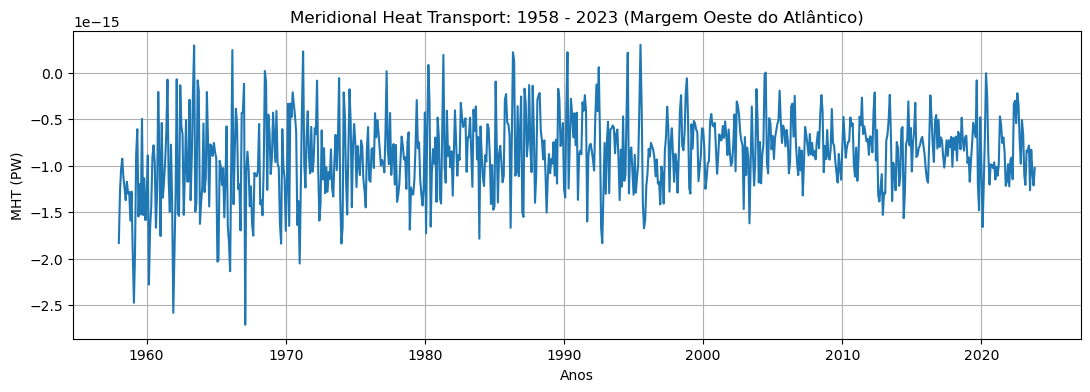

In [17]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_OESTE_em_PW)
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: 1958 - 2023 (Margem Oeste do Atlântico)') #título
plt.grid(True)
plt.savefig('MHT_MARGEM_OESTE')
plt.show()

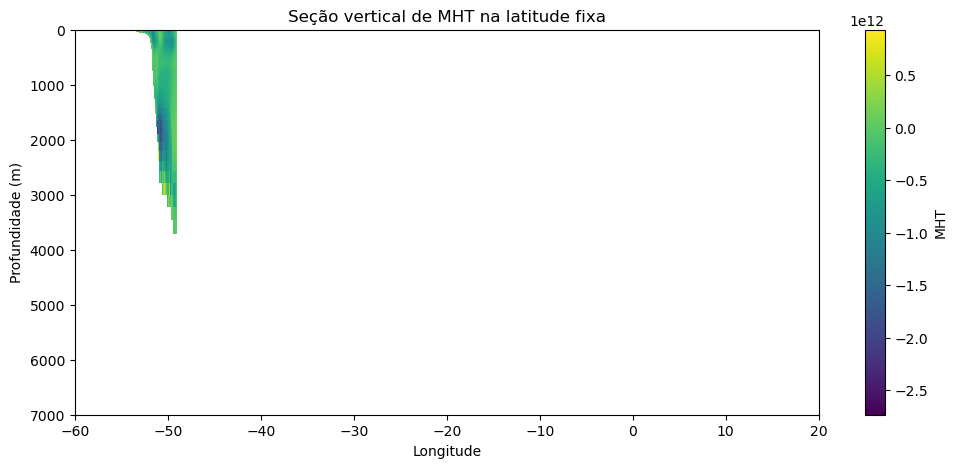

In [9]:
#Plotar dnv

plt.figure(figsize=(12, 5))

plt.pcolormesh(lon2, prof, cumsum, shading='auto', cmap='viridis')

# plt.gca().invert_yaxis()      # profundidade aumenta para baixo
plt.colorbar(label='MHT') #coloca a escala do lado.

x_min = -60
x_max = 20
plt.xlim(x_min, x_max)

y_min = 0
y_max = 7000
plt.ylim(y_max, y_min)

plt.xlabel('Longitude') #eixo x 
plt.ylabel('Profundidade (m)') #eixo y
plt.title('Seção vertical de MHT na latitude fixa') #título
plt.show()

## MARGEM LESTE

In [89]:
lon

masked_array(data=[-6.995e+01, -6.985e+01, -6.975e+01, -6.965e+01,
                   -6.955e+01, -6.945e+01, -6.935e+01, -6.925e+01,
                   -6.915e+01, -6.905e+01, -6.895e+01, -6.885e+01,
                   -6.875e+01, -6.865e+01, -6.855e+01, -6.845e+01,
                   -6.835e+01, -6.825e+01, -6.815e+01, -6.805e+01,
                   -6.795e+01, -6.785e+01, -6.775e+01, -6.765e+01,
                   -6.755e+01, -6.745e+01, -6.735e+01, -6.725e+01,
                   -6.715e+01, -6.705e+01, -6.695e+01, -6.685e+01,
                   -6.675e+01, -6.665e+01, -6.655e+01, -6.645e+01,
                   -6.635e+01, -6.625e+01, -6.615e+01, -6.605e+01,
                   -6.595e+01, -6.585e+01, -6.575e+01, -6.565e+01,
                   -6.555e+01, -6.545e+01, -6.535e+01, -6.525e+01,
                   -6.515e+01, -6.505e+01, -6.495e+01, -6.485e+01,
                   -6.475e+01, -6.465e+01, -6.455e+01, -6.445e+01,
                   -6.435e+01, -6.425e+01, -6.415e+01, -6.405e

In [99]:
valor = -70
idx = np.abs(lon - valor).argmin()
print(idx)

0


In [83]:
lon

masked_array(data=[-6.995e+01, -6.985e+01, -6.975e+01, -6.965e+01,
                   -6.955e+01, -6.945e+01, -6.935e+01, -6.925e+01,
                   -6.915e+01, -6.905e+01, -6.895e+01, -6.885e+01,
                   -6.875e+01, -6.865e+01, -6.855e+01, -6.845e+01,
                   -6.835e+01, -6.825e+01, -6.815e+01, -6.805e+01,
                   -6.795e+01, -6.785e+01, -6.775e+01, -6.765e+01,
                   -6.755e+01, -6.745e+01, -6.735e+01, -6.725e+01,
                   -6.715e+01, -6.705e+01, -6.695e+01, -6.685e+01,
                   -6.675e+01, -6.665e+01, -6.655e+01, -6.645e+01,
                   -6.635e+01, -6.625e+01, -6.615e+01, -6.605e+01,
                   -6.595e+01, -6.585e+01, -6.575e+01, -6.565e+01,
                   -6.555e+01, -6.545e+01, -6.535e+01, -6.525e+01,
                   -6.515e+01, -6.505e+01, -6.495e+01, -6.485e+01,
                   -6.475e+01, -6.465e+01, -6.455e+01, -6.445e+01,
                   -6.435e+01, -6.425e+01, -6.415e+01, -6.405e

In [56]:
cp = 3990       # J/kg/K
ro = 1025       # kg/m3
dx = 8700       # m

MHT_LESTE = []

for k in range(791):

    # =========================
    # LONGITUDE
    # =========================
    lon = theta_datasets[k].variables['lon'][:]

    mask = lon >= 6

    lon = lon[mask]

    # =========================
    # TEMPERATURA
    # =========================
    temp = theta_datasets[k].variables['temp'][:, mask]

    # =========================
    # VELOCIDADE
    # ajusta 901 -> 900
    # =========================
    v_raw = v_datasets[k].variables['v'][:] / 100.0

    v = v_raw[:, :-1]

    v = v[:, mask]

    # =========================
    # PROFUNDIDADE
    # =========================
    prof = theta_datasets[k].variables['lev'][:]

    dz = np.gradient(prof)[:, np.newaxis]

    # =========================
    # FLUXO DE CALOR
    # =========================
    fluxo = temp * v * cp * ro * dx * dz

    soma_atual = np.nansum(fluxo)

    print(f'arquivo {k}: {soma_atual:.3e} W')

    # em PW
    MHT_LESTE.append(soma_atual / 1e15)

arquivo 0: 7.236e+14 W
arquivo 1: 7.841e+14 W
arquivo 2: 6.552e+14 W
arquivo 3: 5.323e+14 W
arquivo 4: 6.506e+14 W
arquivo 5: 8.382e+14 W
arquivo 6: 8.063e+14 W
arquivo 7: 7.398e+14 W
arquivo 8: 7.362e+14 W
arquivo 9: 6.775e+14 W
arquivo 10: 5.534e+14 W
arquivo 11: 7.897e+14 W
arquivo 12: 1.265e+15 W
arquivo 13: 1.320e+15 W
arquivo 14: 1.076e+15 W
arquivo 15: 5.249e+14 W
arquivo 16: 5.335e+14 W
arquivo 17: 7.538e+14 W
arquivo 18: 1.238e+15 W
arquivo 19: 8.673e+14 W
arquivo 20: 7.239e+14 W
arquivo 21: 4.007e+14 W
arquivo 22: 6.177e+14 W
arquivo 23: 7.236e+14 W
arquivo 24: 6.219e+14 W
arquivo 25: 5.212e+14 W
arquivo 26: 1.135e+15 W
arquivo 27: 1.032e+15 W
arquivo 28: 2.598e+14 W
arquivo 29: 7.841e+14 W
arquivo 30: 1.089e+15 W
arquivo 31: 7.682e+14 W
arquivo 32: 2.828e+14 W
arquivo 33: 1.861e+14 W
arquivo 34: 9.035e+14 W
arquivo 35: 8.156e+14 W
arquivo 36: 7.064e+14 W
arquivo 37: 2.883e+14 W
arquivo 38: 4.286e+14 W
arquivo 39: 4.041e+14 W
arquivo 40: 3.149e+14 W
arquivo 41: 6.513e+14 W
ar

In [10]:
cp = 3990       # J/kg/K para água do mar
ro = 1025       # kg/m3
dx = 8700       # m
MHT_LESTE = []

for k in range(791):
    lon2  = theta_datasets[k].variables['lon'][:]
    lon2 = lon2[(lon2 >= 6)]
    temp = theta_datasets[k].variables['temp'][:]
    
    v    = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s
    prof = theta_datasets[k].variables['lev'][:]

    cumsum = np.zeros((len(prof), len(lon2)))

    for i in range(len(lon2)):
        for j in range(len(prof)):
            if j == 0:
                dz = prof[0]
            else:
                dz = prof[j] - prof[j-1]

            cumsum[j][i] = temp[j][i+524] * v[j][i+524] * cp * ro * dx * dz

    soma_atual = np.nansum(cumsum)
    print(f'soma do arquivo {k} = {soma_atual:.3e} W')
    MHT_LESTE.append(soma_atual)

/tmp/ipykernel_4896/470452246.py:23: UserWarning: Warning: converting a masked element to nan.
  cumsum[j][i] = temp[j][i+524] * v[j][i+524] * cp * ro * dx * dz


soma do arquivo 0 = 3.882e+14 W
soma do arquivo 1 = 4.448e+14 W
soma do arquivo 2 = 4.299e+14 W
soma do arquivo 3 = 4.341e+14 W
soma do arquivo 4 = 4.149e+14 W
soma do arquivo 5 = 4.645e+14 W
soma do arquivo 6 = 4.258e+14 W
soma do arquivo 7 = 3.341e+14 W
soma do arquivo 8 = 2.931e+14 W
soma do arquivo 9 = 2.875e+14 W
soma do arquivo 10 = 2.578e+14 W
soma do arquivo 11 = 2.638e+14 W
soma do arquivo 12 = 1.917e+14 W
soma do arquivo 13 = 1.836e+14 W
soma do arquivo 14 = 1.959e+14 W
soma do arquivo 15 = 1.255e+14 W
soma do arquivo 16 = 9.468e+13 W
soma do arquivo 17 = 6.311e+13 W
soma do arquivo 18 = 1.502e+14 W
soma do arquivo 19 = 2.259e+14 W
soma do arquivo 20 = 2.719e+14 W
soma do arquivo 21 = 1.817e+14 W
soma do arquivo 22 = 3.969e+13 W
soma do arquivo 23 = 1.230e+13 W
soma do arquivo 24 = -6.254e+13 W
soma do arquivo 25 = -8.078e+13 W
soma do arquivo 26 = -2.279e+13 W
soma do arquivo 27 = 1.348e+14 W
soma do arquivo 28 = 2.294e+14 W
soma do arquivo 29 = 2.247e+14 W
soma do arquivo 3

In [18]:
MHT_LESTE_em_PW = []

for i in range (len(MHT_LESTE)):
    MHT_LESTE_em_PW.append(MHT_LESTE[i] / (10**15))

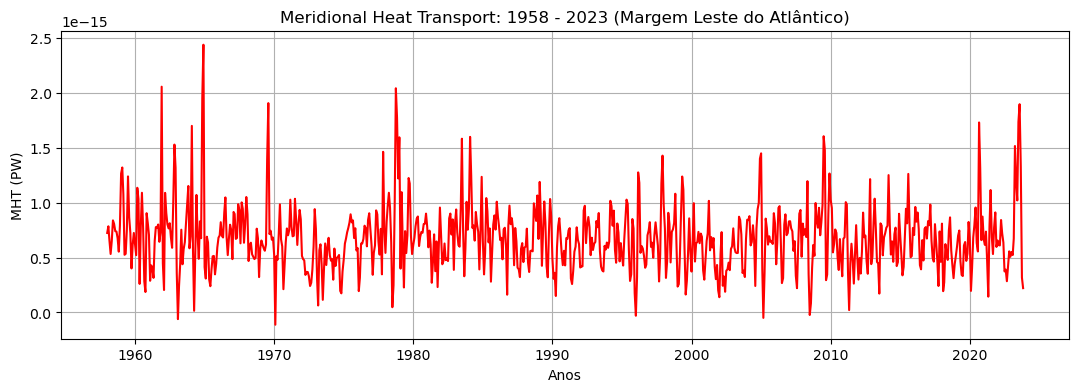

In [19]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_LESTE_em_PW, color = 'red')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: 1958 - 2023 (Margem Leste do Atlântico)') #título
plt.savefig('MHT_MARGEM_LESTE')
plt.grid(True)
plt.show()

In [15]:
t2 = []

for i in range (len(datas)):
    inicio = datetime(1, 1, 1)
    data = inicio + timedelta(days=datas[i])
    t.append(data)

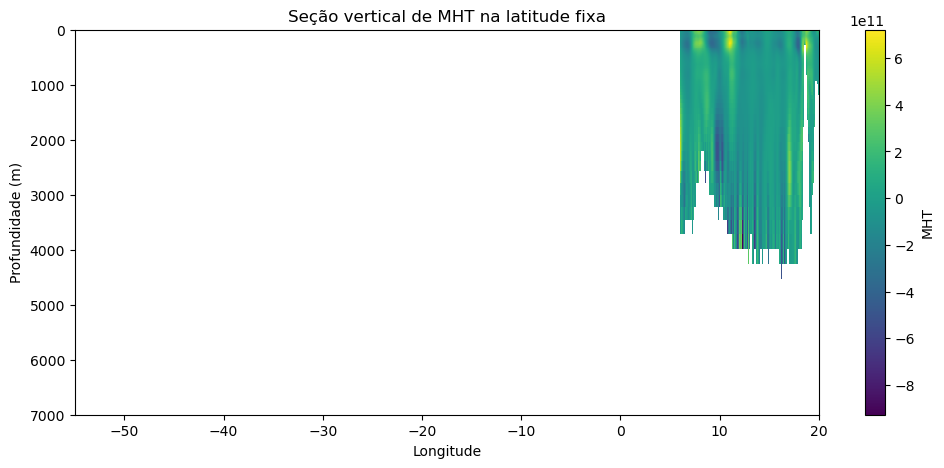

In [16]:
plt.figure(figsize=(12, 5))

plt.pcolormesh(lon2, prof, cumsum, shading='auto', cmap='viridis')

# plt.gca().invert_yaxis()      # profundidade aumenta para baixo
plt.colorbar(label='MHT') #coloca a escala do lado.

x_min = -55
x_max = 20
plt.xlim(x_min, x_max)

y_min = 0
y_max = 7000
plt.ylim(y_max, y_min)

plt.xlabel('Longitude') #eixo x 
plt.ylabel('Profundidade (m)') #eixo y
plt.title('Seção vertical de MHT na latitude fixa') #título
plt.show()

In [17]:
len(MHT_LESTE)

791

In [18]:
len(MHT_OESTE)

791

#### DIFERENÇA LESTE-OESTE ESTÁ ERRADA REFAZER

In [113]:
## DIFERENÇA LESTE - OESTE (não sei se serve pra muita coisa)

dif = []

for i in range(len(MHT_LESTE)):
    diferenca = MHT_LESTE[i] - MHT_OESTE[i]
    dif.append(diferenca)
    print(f'Diferença ano {i} = {diferenca:.3e} W')

Diferença ano 0 = 2.595e+15 W
Diferença ano 1 = 2.042e+15 W
Diferença ano 2 = 2.152e+15 W
Diferença ano 3 = 2.102e+15 W
Diferença ano 4 = 2.031e+15 W
Diferença ano 5 = 1.918e+15 W
Diferença ano 6 = 1.966e+15 W
Diferença ano 7 = 2.044e+15 W
Diferença ano 8 = 2.109e+15 W
Diferença ano 9 = 2.026e+15 W
Diferença ano 10 = 1.990e+15 W
Diferença ano 11 = 2.010e+15 W
Diferença ano 12 = 1.808e+15 W
Diferença ano 13 = 2.018e+15 W
Diferença ano 14 = 1.886e+15 W
Diferença ano 15 = 2.021e+15 W
Diferença ano 16 = 1.724e+15 W
Diferença ano 17 = 1.553e+15 W
Diferença ano 18 = 1.581e+15 W
Diferença ano 19 = 1.738e+15 W
Diferença ano 20 = 1.679e+15 W
Diferença ano 21 = 1.750e+15 W
Diferença ano 22 = 2.033e+15 W
Diferença ano 23 = 1.783e+15 W
Diferença ano 24 = 1.961e+15 W
Diferença ano 25 = 1.838e+15 W
Diferença ano 26 = 2.075e+15 W
Diferença ano 27 = 1.640e+15 W
Diferença ano 28 = 1.824e+15 W
Diferença ano 29 = 1.727e+15 W
Diferença ano 30 = 1.475e+15 W
Diferença ano 31 = 1.440e+15 W
Diferença ano 32 =

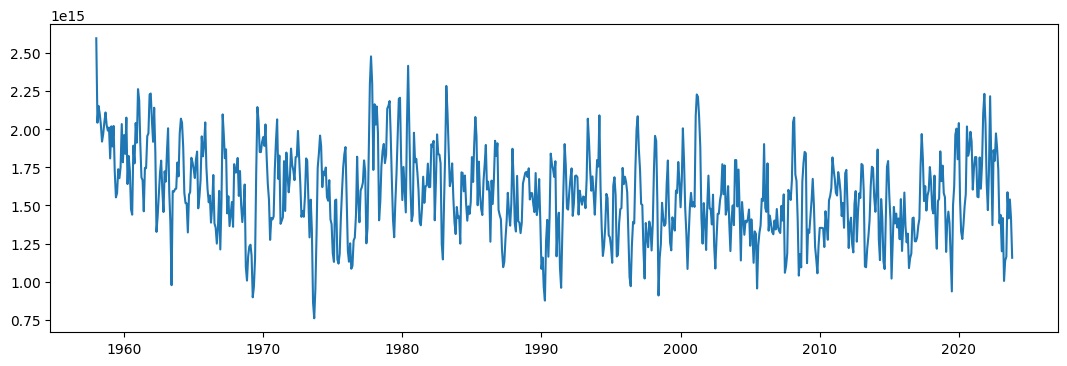

In [114]:
plt.figure(figsize=(13, 4))
plt.plot(t,dif)

In [115]:
## SOMA LESTE + OESTE

som = []

for i in range(len(MHT_LESTE)):
    diferenca2 = MHT_LESTE[i] + MHT_OESTE[i]
    som.append(diferenca2)
    print(f'Diferença ano {i} = {diferenca2:.3e} W')

Diferença ano 0 = -3.361e+14 W
Diferença ano 1 = 1.140e+14 W
Diferença ano 2 = 6.648e+12 W
Diferença ano 3 = 6.265e+13 W
Diferença ano 4 = 2.131e+14 W
Diferença ano 5 = 2.581e+14 W
Diferença ano 6 = 1.146e+14 W
Diferença ano 7 = 2.236e+13 W
Diferença ano 8 = 3.878e+13 W
Diferença ano 9 = -1.843e+13 W
Diferença ano 10 = -6.566e+12 W
Diferença ano 11 = -2.099e+14 W
Diferença ano 12 = -9.710e+12 W
Diferença ano 13 = -2.762e+13 W
Diferença ano 14 = -1.774e+13 W
Diferença ano 15 = -1.025e+13 W
Diferença ano 16 = 3.155e+14 W
Diferença ano 17 = 9.871e+13 W
Diferença ano 18 = 5.172e+14 W
Diferença ano 19 = 8.473e+13 W
Diferença ano 20 = 1.467e+14 W
Diferença ano 21 = -1.743e+13 W
Diferença ano 22 = -1.546e+14 W
Diferença ano 23 = -1.223e+13 W
Diferença ano 24 = -1.047e+14 W
Diferença ano 25 = -1.615e+14 W
Diferença ano 26 = -2.823e+14 W
Diferença ano 27 = 1.362e+13 W
Diferença ano 28 = -2.536e+14 W
Diferença ano 29 = 3.851e+14 W
Diferença ano 30 = 1.564e+14 W
Diferença ano 31 = 1.622e+14 W
Dif

## INTERIOR 

In [57]:
cp = 3990       # J/kg/K
ro = 1025       # kg/m3
dx = 8700       # m

MHT_INTERIOR = []

for k in range(791):

    # =========================
    # LONGITUDE
    # =========================
    lon = theta_datasets[k].variables['lon'][:]

    mask = (lon >= -49) & (lon <= 6)

    lon = lon[mask]

    # =========================
    # TEMPERATURA
    # =========================
    temp = theta_datasets[k].variables['temp'][:, mask]

    # =========================
    # VELOCIDADE
    # ajusta 901 -> 900
    # =========================
    v_raw = v_datasets[k].variables['v'][:] / 100.0

    v = v_raw[:, :-1]

    v = v[:, mask]

    # =========================
    # PROFUNDIDADE
    # =========================
    prof = theta_datasets[k].variables['lev'][:]

    dz = np.gradient(prof)[:, np.newaxis]

    # =========================
    # FLUXO DE CALOR
    # =========================
    fluxo = temp * v * cp * ro * dx * dz

    soma_atual = np.nansum(fluxo)

    print(f'arquivo {k}: {soma_atual:.3e} W')

    # em PW
    MHT_INTERIOR.append(soma_atual / 1e15)

arquivo 0: 7.643e+14 W
arquivo 1: 6.161e+14 W
arquivo 2: 3.911e+14 W
arquivo 3: 4.548e+14 W
arquivo 4: 6.848e+14 W
arquivo 5: 6.630e+14 W
arquivo 6: 6.776e+14 W
arquivo 7: 4.480e+14 W
arquivo 8: 5.971e+14 W
arquivo 9: 5.798e+14 W
arquivo 10: 1.031e+15 W
arquivo 11: 2.721e+14 W
arquivo 12: 6.501e+14 W
arquivo 13: 1.135e+15 W
arquivo 14: 8.725e+14 W
arquivo 15: 3.317e+14 W
arquivo 16: 3.915e+14 W
arquivo 17: 8.873e+14 W
arquivo 18: 4.841e+14 W
arquivo 19: 7.356e+14 W
arquivo 20: -8.149e+13 W
arquivo 21: 1.103e+15 W
arquivo 22: 3.509e+14 W
arquivo 23: 8.447e+14 W
arquivo 24: 6.263e+14 W
arquivo 25: 2.044e+14 W
arquivo 26: 8.399e+14 W
arquivo 27: 6.483e+14 W
arquivo 28: 9.117e+14 W
arquivo 29: 5.204e+14 W
arquivo 30: -1.425e+14 W
arquivo 31: 3.802e+14 W
arquivo 32: 1.388e+15 W
arquivo 33: 1.062e+15 W
arquivo 34: -7.554e+14 W
arquivo 35: 2.171e+14 W
arquivo 36: 9.036e+14 W
arquivo 37: 2.218e+14 W
arquivo 38: 9.626e+14 W
arquivo 39: 1.010e+15 W
arquivo 40: 6.638e+14 W
arquivo 41: 4.127e+14 W

In [19]:
cp = 3990       # J/kg/K para água do mar
ro = 1025       # kg/m3
dx = 8700       # m
MHT_INTERIOR = []

for k in range(791):
    lon2  = theta_datasets[k].variables['lon'][:]
    lon2 = lon2[(lon2 >= -49) & (lon2 <= 6)]
    temp = theta_datasets[k].variables['temp'][:]
    v    = v_datasets[k].variables['v'][:] / 100.0  # cm/s -> m/s
    prof = theta_datasets[k].variables['lev'][:]

    cumsum = np.zeros((len(prof), len(lon2)))

    for i in range(len(lon2)):
        for j in range(len(prof)):
            if j == 0:
                dz = prof[0]
            else:
                dz = prof[j] - prof[j-1]

            cumsum[j][i] = temp[j][i] * v[j][i] * cp * ro * dx * dz

    soma_atual = np.nansum(cumsum)
    print(f'soma do arquivo {k} = {soma_atual:.3e} W')
    MHT_INTERIOR.append(soma_atual)

/tmp/ipykernel_4896/774100617.py:22: UserWarning: Warning: converting a masked element to nan.
  cumsum[j][i] = temp[j][i] * v[j][i] * cp * ro * dx * dz


soma do arquivo 0 = -1.463e+15 W
soma do arquivo 1 = -8.731e+14 W
soma do arquivo 2 = -9.040e+14 W
soma do arquivo 3 = -8.043e+14 W
soma do arquivo 4 = -6.789e+14 W
soma do arquivo 5 = -6.100e+14 W
soma do arquivo 6 = -7.566e+14 W
soma do arquivo 7 = -8.977e+14 W
soma do arquivo 8 = -9.579e+14 W
soma do arquivo 9 = -9.444e+14 W
soma do arquivo 10 = -8.576e+14 W
soma do arquivo 11 = -9.802e+14 W
soma do arquivo 12 = -7.717e+14 W
soma do arquivo 13 = -8.768e+14 W
soma do arquivo 14 = -8.091e+14 W
soma do arquivo 15 = -8.904e+14 W
soma do arquivo 16 = -5.441e+14 W
soma do arquivo 17 = -5.497e+14 W
soma do arquivo 18 = -3.232e+14 W
soma do arquivo 19 = -6.553e+14 W
soma do arquivo 20 = -6.161e+14 W
soma do arquivo 21 = -7.526e+14 W
soma do arquivo 22 = -9.673e+14 W
soma do arquivo 23 = -8.081e+14 W
soma do arquivo 24 = -9.798e+14 W
soma do arquivo 25 = -1.022e+15 W
soma do arquivo 26 = -1.262e+15 W
soma do arquivo 27 = -8.551e+14 W
soma do arquivo 28 = -1.040e+15 W
soma do arquivo 29 = -5.

In [26]:
len(MHT_INTERIOR)

791

In [20]:
MHT_INTERIOR_em_PW = []

for i in range (len(MHT_INTERIOR)):
    MHT_INTERIOR_em_PW.append(MHT_INTERIOR[i] / (10**15))

In [21]:
len(MHT_INTERIOR_em_PW)

791

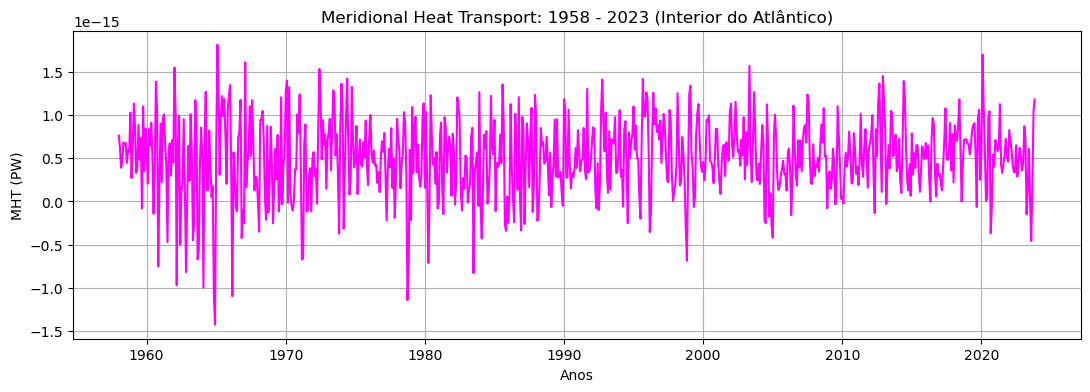

In [22]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_INTERIOR_em_PW, color = 'magenta')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: 1958 - 2023 (Interior do Atlântico)') #título
plt.grid(True)
plt.savefig('MHT_Interior')
plt.show()

## CONTRIBUIÇÃO POR MARGEM

In [66]:
import pandas as pd

df = pd.DataFrame({
    'data': t,          # sua lista de datetime
    'MHT_OESTE': MHT_OESTE    # sua lista de MHT
})

df['data'] = pd.to_datetime(df['data'])

In [67]:
df['decada'] = (df['data'].dt.year // 10) * 10

In [68]:
media_decada = df.groupby('decada')['MHT_OESTE'].mean()
print(media_decada)

decada
1950   -1.347292
1960   -1.042740
1970   -0.929573
1980   -0.799717
1990   -0.827936
2000   -0.765803
2010   -0.802363
2020   -0.871365
Name: MHT_OESTE, dtype: float64


In [75]:
import pandas as pd

df2 = pd.DataFrame({
    'data': t,          # sua lista de datetime
    'MHT_LESTE': MHT_LESTE    # sua lista de MHT
})

df2['data'] = pd.to_datetime(df['data'])

In [76]:
df2['decada'] = (df2['data'].dt.year // 10) * 10

In [78]:
media_decada = df2.groupby('decada')['MHT_LESTE'].mean()
print(media_decada)

decada
1950    0.772109
1960    0.723237
1970    0.647899
1980    0.708890
1990    0.638627
2000    0.646534
2010    0.624815
2020    0.745989
Name: MHT_LESTE, dtype: float64


In [79]:
import pandas as pd

df3 = pd.DataFrame({
    'data': t,          # sua lista de datetime
    'MHT_INTERIOR': MHT_INTERIOR    # sua lista de MHT
})

df3['data'] = pd.to_datetime(df['data'])

In [80]:
df3['decada'] = (df3['data'].dt.year // 10) * 10

In [81]:
media_decada = df3.groupby('decada')['MHT_INTERIOR'].mean()
print(media_decada)

decada
1950    0.620141
1960    0.429401
1970    0.512949
1980    0.418588
1990    0.572582
2000    0.517674
2010    0.563707
2020    0.523235
Name: MHT_INTERIOR, dtype: float64


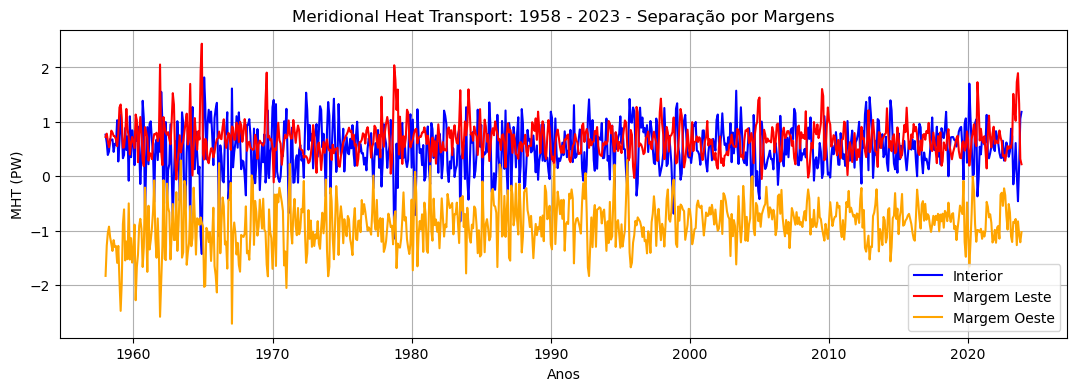

In [63]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_INTERIOR, color = 'blue', label = 'Interior')
plt.plot(t,MHT_LESTE, color = 'red', label = 'Margem Leste')
plt.plot(t,MHT_OESTE, color = 'orange', label = 'Margem Oeste')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: 1958 - 2023 - Separação por Margens') #título
plt.grid(True)
plt.legend()
plt.savefig('MHT_MARGENS_TESTE')
plt.show()

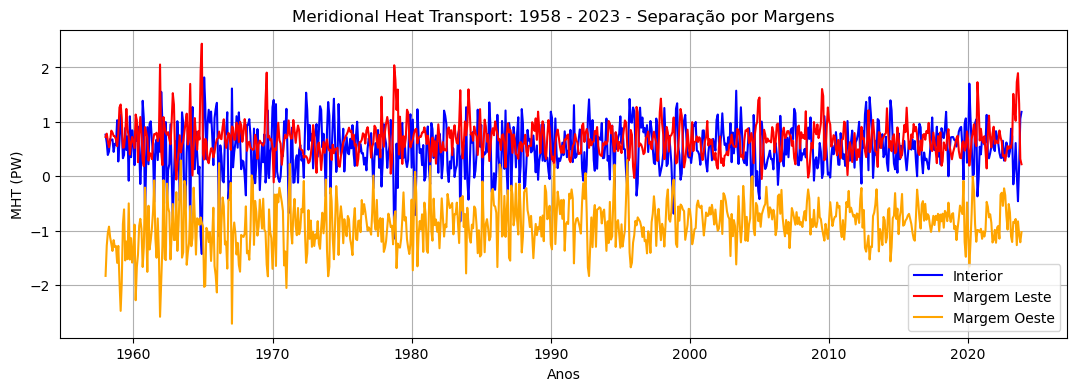

In [82]:
plt.figure(figsize=(13, 4))
plt.plot(t,MHT_INTERIOR, color = 'blue', label = 'Interior')
plt.plot(t,MHT_LESTE, color = 'red', label = 'Margem Leste')
plt.plot(t,MHT_OESTE, color = 'orange', label = 'Margem Oeste')
plt.xlabel('Anos') #eixo x 
plt.ylabel('MHT (PW)') #eixo y
plt.title('Meridional Heat Transport: 1958 - 2023 - Separação por Margens') #título
plt.grid(True)
plt.legend()
plt.savefig('MHT_MARGENS_TESTE')
plt.show()


In [83]:
mean_int_bruto = np.mean(MHT_INTERIOR)
mean_oes_bruto = np.mean(MHT_OESTE)
mean_les_bruto = np.mean(MHT_LESTE)

In [84]:
int_contrib = []
oes_contrib = []
les_contrib = []
total_abs_2 = []

for i in range(len(MHT_INTERIOR)):

    total_abs = (
        abs(MHT_INTERIOR[i]) +
        abs(MHT_OESTE[i]) +
        abs(MHT_LESTE[i])
    )

    if total_abs != 0:
        int_contrib.append(100 * abs(MHT_INTERIOR[i]) / total_abs)
        oes_contrib.append(100 * abs(MHT_OESTE[i]) / total_abs)
        les_contrib.append(100 * abs(MHT_LESTE[i]) / total_abs)
    else:
        int_contrib.append(np.nan)
        oes_contrib.append(np.nan)
        les_contrib.append(np.nan)

In [85]:
len(int_contrib)

791

In [86]:
mean_int = np.mean(int_contrib)
mean_oes = np.mean(oes_contrib)
mean_les = np.mean(les_contrib)

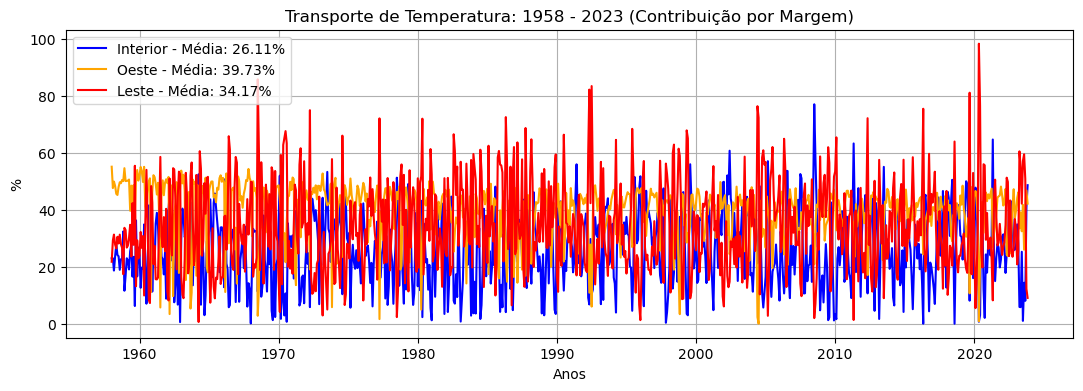

In [87]:
plt.figure(figsize=(13, 4))
plt.plot(t, int_contrib, label=f'Interior - Média: {mean_int:.2f}%', color='blue')
plt.plot(t, oes_contrib, label=f'Oeste - Média: {mean_oes:.2f}%', color='orange')
plt.plot(t, les_contrib, label=f'Leste - Média: {mean_les:.2f}%', color='red')
plt.xlabel('Anos') #eixo x 
plt.ylabel('%') #eixo y
plt.title('Transporte de Temperatura: 1958 - 2023 (Contribuição por Margem)') #título
plt.grid(True)
plt.legend()
plt.savefig('MHT_Comparativo_Margens')
plt.show()

# FOURIER (CICLOS)

## Ciclos pro MHT Total

### Remoção da Média dos Meses

In [68]:
MHT_TOTAL_SEM_ANUAL = []
for i in range (len(MHT_total_em_PW)):
    MHT_TOTAL_SEM_ANUAL.append(MHT_total_em_PW[i] - serie_toda[i])
                

In [69]:
MHT_TOTAL_SEM_ANUAL

[np.float32(-0.52458054),
 np.float32(-0.051858567),
 np.float32(-0.17601304),
 np.float32(-0.23620689),
 np.float32(-0.24103196),
 np.float32(-0.2767273),
 np.float32(-0.3448015),
 np.float32(-0.35764444),
 np.float32(-0.22410496),
 np.float32(-0.22290483),
 np.float32(-0.21750008),
 np.float32(-0.45500883),
 np.float32(-0.19416335),
 np.float32(-0.19250512),
 np.float32(-0.20345052),
 np.float32(-0.31491446),
 np.float32(-0.14262876),
 np.float32(-0.4389162),
 np.float32(0.05559218),
 np.float32(-0.2954826),
 np.float32(-0.11543143),
 np.float32(-0.2262105),
 np.float32(-0.36942366),
 np.float32(-0.26008686),
 np.float32(-0.29390445),
 np.float32(-0.32468635),
 np.float32(-0.464731),
 np.float32(-0.28594851),
 np.float32(-0.70980644),
 np.float32(-0.14955074),
 np.float32(-0.29273432),
 np.float32(-0.197762),
 np.float32(-0.2547838),
 np.float32(-0.25646806),
 np.float32(-0.264391),
 np.float32(-0.114175856),
 np.float32(-0.33104417),
 np.float32(-0.19486605),
 np.float32(-0.13523513

### FFT

In [96]:
import numpy as np
from scipy.fft import fft, ifft, fftfreq

# Supondo:
# MHT_total_em_PW -> array 1D
# t -> lista de datetime mensais

# Número de pontos
N = len(MHT_TOTAL_SEM_ANUAL)

# Intervalo de amostragem (mensal = 1 mês)
dt = 1  # unidade: mês

# FFT
fft_vals = fft(MHT_TOTAL_SEM_ANUAL)

# Frequências
freqs = fftfreq(N, d=dt)

# Frequências dos ciclos que queremos remover (em ciclos por mês)
f_12 = 1/12
f_6 = 1/6
f_3 = 1/3
f_780 = 1/780
f_min = 1 / 200

# Tolerância para pegar os bins corretos
tol = 1e-4

# Criar máscara para remover essas frequências (e simétricas negativas)
mask = (
    # ciclos específicos
    (np.abs(freqs - f_12) < tol) | (np.abs(freqs + f_12) < tol) |
    (np.abs(freqs - f_6) < tol)  | (np.abs(freqs + f_6) < tol)  |
    (np.abs(freqs - f_3) < tol)  | (np.abs(freqs + f_3) < tol)  |
    (np.abs(freqs - f_780) < tol)| (np.abs(freqs + f_780) < tol) |

    # 🔴 remover ciclos maiores que N/2 meses (baixa frequência)
    (np.abs(freqs) < f_min)
)

# Zerar essas componentes
fft_vals[mask] = 0

# Reconstruir sinal sem esses ciclos
MHT_filtrado = np.real(ifft(fft_vals))

Maiores amplitudes:

Período: 197.75 meses | Amplitude: 12.60
Período: 87.89 meses | Amplitude: 12.19
Período: 158.20 meses | Amplitude: 10.72
Período: 131.83 meses | Amplitude: 8.94
Período: 43.94 meses | Amplitude: 8.61
Período: 19.29 meses | Amplitude: 8.14
Período: 21.38 meses | Amplitude: 7.63
Período: 10.99 meses | Amplitude: 6.98
Período: 30.42 meses | Amplitude: 6.74
Período: 14.12 meses | Amplitude: 6.73


/tmp/ipykernel_4637/91514723.py:18: RuntimeWarning: divide by zero encountered in divide
  periods = np.where(freqs != 0, 1/freqs, np.inf)


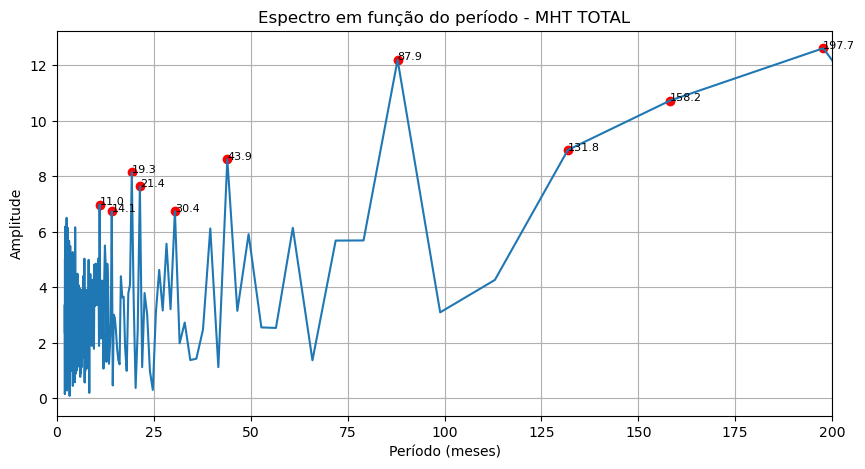

In [98]:
import matplotlib.pyplot as plt

# Quantos maiores picos deseja
top_n = 10

# Índices das maiores amplitudes
idx_top = np.argsort(amplitude_pos)[-top_n:][::-1]

print("Maiores amplitudes:\n")

for i in idx_top:
    print(f"Período: {periods_pos[i]:.2f} meses | Amplitude: {amplitude_pos[i]:.2f}")

# Magnitude da FFT (antes de remover, pra visualizar os ciclos)
amplitude = np.abs(fft_vals)

# Evitar divisão por zero
periods = np.where(freqs != 0, 1/freqs, np.inf)

# Pegar só frequências positivas
mask_pos = freqs > 0

periods_pos = periods[mask_pos]
amplitude_pos = amplitude[mask_pos]

# Plot
plt.figure(figsize=(10,5))
plt.plot(periods_pos, amplitude_pos)

# Destacar maiores picos
plt.scatter(periods_pos[idx_top],
            amplitude_pos[idx_top],
            color='red')

for i in idx_top:
    plt.text(periods_pos[i],
             amplitude_pos[i],
             f"{periods_pos[i]:.1f}",
             fontsize=8)

plt.xlabel("Período (meses)")
plt.ylabel("Amplitude")
plt.title("Espectro em função do período - MHT TOTAL")
plt.xlim(0, 200)
plt.grid()
plt.savefig('Ciclos TOTAIS')
plt.show()

## Ciclos pra superfície

In [81]:
jansup = []
fevsup = []
marsup = []
aprsup = []
maysup = []
junsup = []
julsup = []
augsup = []
sepsup = []
octosup = []
novsup = []
dezsup = []

for i in range(0, len(MHT_superficie_PW) - 11, 12):
    jansup.append(MHT_superficie_PW[i])
    fevsup.append(MHT_superficie_PW[i+1])
    marsup.append(MHT_superficie_PW[i+2])
    aprsup.append(MHT_superficie_PW[i+3])
    maysup.append(MHT_superficie_PW[i+4])
    junsup.append(MHT_superficie_PW[i+5])
    julsup.append(MHT_superficie_PW[i+6])
    augsup.append(MHT_superficie_PW[i+7])
    sepsup.append(MHT_superficie_PW[i+8])
    octosup.append(MHT_superficie_PW[i+9])
    novsup.append(MHT_superficie_PW[i+10])
    dezsup.append(MHT_superficie_PW[i+11])

In [116]:
meses_dados_sup = [jansup, fevsup, marsup, aprsup, maysup, junsup, julsup, augsup, sepsup, octosup, novsup, dezsup]
medias_sup = [np.mean(m) for m in meses_dados_sup]

In [117]:
medias_sup

[np.float32(0.44516346),
 np.float32(0.4178909),
 np.float32(0.44371447),
 np.float32(0.56362337),
 np.float32(0.7280444),
 np.float32(0.8158247),
 np.float32(0.73529005),
 np.float32(0.637752),
 np.float32(0.5122589),
 np.float32(0.4432442),
 np.float32(0.4604355),
 np.float32(0.5052336)]

In [118]:
serie_toda_sup = medias_sup * 66

In [119]:
serie_toda_sup.pop()

np.float32(0.5052336)

In [120]:
len(serie_toda_sup)

791

In [121]:
MHT_SUP_SEM_ANUAL = []
for i in range (len(MHT_superficie_PW)):
    MHT_SUP_SEM_ANUAL.append(MHT_superficie_PW[i] - serie_toda_sup[i])

In [123]:
import numpy as np
from scipy.fft import fft, ifft, fftfreq

# Supondo:
# MHT_total_em_PW -> array 1D
# t -> lista de datetime mensais

# Número de pontos
N = len(MHT_SUP_SEM_ANUAL)

# Intervalo de amostragem (mensal = 1 mês)
dt = 1  # unidade: mês

# FFT
fft_vals = fft(MHT_SUP_SEM_ANUAL)

# Frequências
freqs = fftfreq(N, d=dt)

# Frequências dos ciclos que queremos remover (em ciclos por mês)
f_12 = 1/12
f_6 = 1/6
f_3 = 1/3
f_780 = 1/780
f_min = 1 / 200

# Tolerância para pegar os bins corretos
tol = 1e-4

# Criar máscara para remover essas frequências (e simétricas negativas)
mask = (
    # ciclos específicos
    (np.abs(freqs - f_12) < tol) | (np.abs(freqs + f_12) < tol) |
    (np.abs(freqs - f_6) < tol)  | (np.abs(freqs + f_6) < tol)  |
    (np.abs(freqs - f_3) < tol)  | (np.abs(freqs + f_3) < tol)  |
    (np.abs(freqs - f_780) < tol)| (np.abs(freqs + f_780) < tol) |

    # 🔴 remover ciclos maiores que N/2 meses (baixa frequência)
    (np.abs(freqs) < f_min)
)

# Zerar essas componentes
fft_vals[mask] = 0

# Reconstruir sinal sem esses ciclos
MHT_filtrado = np.real(ifft(fft_vals))

Maiores amplitudes:

Período: 197.75 meses | Amplitude: 13.29
Período: 87.89 meses | Amplitude: 12.87
Período: 158.20 meses | Amplitude: 11.20
Período: 43.94 meses | Amplitude: 9.26
Período: 131.83 meses | Amplitude: 9.00
Período: 21.38 meses | Amplitude: 7.79
Período: 19.29 meses | Amplitude: 7.61
Período: 10.99 meses | Amplitude: 7.33
Período: 30.42 meses | Amplitude: 7.17
Período: 2.11 meses | Amplitude: 6.77


/tmp/ipykernel_4637/3098798136.py:18: RuntimeWarning: divide by zero encountered in divide
  periods = np.where(freqs != 0, 1/freqs, np.inf)


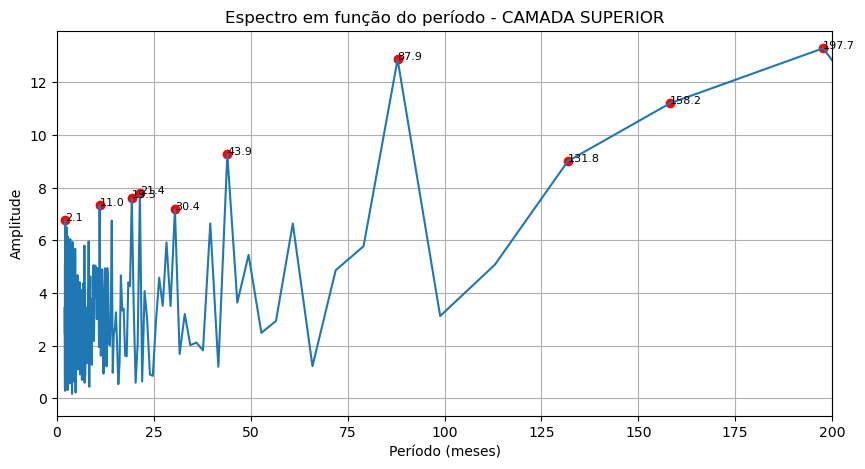

In [124]:
import matplotlib.pyplot as plt

# Quantos maiores picos deseja
top_n = 10

# Índices das maiores amplitudes
idx_top = np.argsort(amplitude_pos)[-top_n:][::-1]

print("Maiores amplitudes:\n")

for i in idx_top:
    print(f"Período: {periods_pos[i]:.2f} meses | Amplitude: {amplitude_pos[i]:.2f}")

# Magnitude da FFT (antes de remover, pra visualizar os ciclos)
amplitude = np.abs(fft_vals)

# Evitar divisão por zero
periods = np.where(freqs != 0, 1/freqs, np.inf)

# Pegar só frequências positivas
mask_pos = freqs > 0

periods_pos = periods[mask_pos]
amplitude_pos = amplitude[mask_pos]

# Plot
plt.figure(figsize=(10,5))
plt.plot(periods_pos, amplitude_pos)

# Destacar maiores picos
plt.scatter(periods_pos[idx_top],
            amplitude_pos[idx_top],
            color='red')

for i in idx_top:
    plt.text(periods_pos[i],
             amplitude_pos[i],
             f"{periods_pos[i]:.1f}",
             fontsize=8)

plt.xlabel("Período (meses)")
plt.ylabel("Amplitude")
plt.title("Espectro em função do período - CAMADA SUPERIOR")
plt.xlim(0, 200)
plt.grid()
plt.savefig('CIclos Superior')
plt.show()

## Ciclos pra NADW

In [125]:
janmid = []
fevmid= []
marmid = []
aprmid = []
maymid = []
junmid = []
julmid = []
augmid = []
sepmid = []
octomid = []
novmid = []
dezmid = []

for i in range(0, len(MHT_transição_PW) - 11, 12):
    janmid.append(MHT_transição_PW[i])
    fevmid.append(MHT_transição_PW[i+1])
    marmid.append(MHT_transição_PW[i+2])
    aprmid.append(MHT_transição_PW[i+3])
    maymid.append(MHT_transição_PW[i+4])
    junmid.append(MHT_transição_PW[i+5])
    julmid.append(MHT_transição_PW[i+6])
    augmid.append(MHT_transição_PW[i+7])
    sepmid.append(MHT_transição_PW[i+8])
    octomid.append(MHT_transição_PW[i+9])
    novmid.append(MHT_transição_PW[i+10])
    dezmid.append(MHT_transição_PW[i+11])

In [126]:
meses_dados_mid = [janmid, fevmid, marmid, aprmid, maymid, junmid, julmid, augmid, sepmid, octomid, novmid, dezmid]
medias_mid = [np.mean(m) for m in meses_dados_mid]

In [127]:
medias_mid

[np.float32(-0.26385945),
 np.float32(-0.25901002),
 np.float32(-0.26582226),
 np.float32(-0.26778588),
 np.float32(-0.27359125),
 np.float32(-0.27862364),
 np.float32(-0.27450025),
 np.float32(-0.2616907),
 np.float32(-0.25314614),
 np.float32(-0.24356583),
 np.float32(-0.2528482),
 np.float32(-0.26327628)]

In [128]:
serie_toda_mid = medias_mid * 66

In [129]:
MHT_MID_SEM_ANUAL = []
for i in range (len(MHT_transição_PW)):
    MHT_MID_SEM_ANUAL.append(MHT_transição_PW[i] - serie_toda_mid[i])

In [130]:
import numpy as np
from scipy.fft import fft, ifft, fftfreq

# Supondo:
# MHT_total_em_PW -> array 1D
# t -> lista de datetime mensais{

# Número de pontos
N = len(MHT_MID_SEM_ANUAL)

# Intervalo de amostragem (mensal = 1 mês)
dt = 1  # unidade: mês

# FFT
fft_vals = fft(MHT_MID_SEM_ANUAL)

# Frequências
freqs = fftfreq(N, d=dt)

# Frequências dos ciclos que queremos remover (em ciclos por mês)
f_12 = 1/12
f_6 = 1/6
f_3 = 1/3
f_780 = 1/780
f_min = 1 / 200

# Tolerância para pegar os bins corretos
tol = 1e-4

# Criar máscara para remover essas frequências (e simétricas negativas)
mask = (
    # ciclos específicos
    (np.abs(freqs - f_12) < tol) | (np.abs(freqs + f_12) < tol) |
    (np.abs(freqs - f_6) < tol)  | (np.abs(freqs + f_6) < tol)  |
    (np.abs(freqs - f_3) < tol)  | (np.abs(freqs + f_3) < tol)  |
    (np.abs(freqs - f_780) < tol)| (np.abs(freqs + f_780) < tol) |

    # 🔴 remover ciclos maiores que N/2 meses (baixa frequência)
    (np.abs(freqs) < f_min)
)

# Zerar essas componentes
fft_vals[mask] = 0

# Reconstruir sinal sem esses ciclos
MHT_filtrado = np.real(ifft(fft_vals))

Maiores amplitudes:

Período: 4.57 meses | Amplitude: 2.12
Período: 9.65 meses | Amplitude: 1.39
Período: 15.21 meses | Amplitude: 1.30
Período: 2.57 meses | Amplitude: 1.26
Período: 4.04 meses | Amplitude: 1.25
Período: 6.23 meses | Amplitude: 1.24
Período: 12.17 meses | Amplitude: 1.23
Período: 18.83 meses | Amplitude: 1.22
Período: 3.70 meses | Amplitude: 1.22
Período: 2.76 meses | Amplitude: 1.22


/tmp/ipykernel_4637/3576757328.py:18: RuntimeWarning: divide by zero encountered in divide
  periods = np.where(freqs != 0, 1/freqs, np.inf)


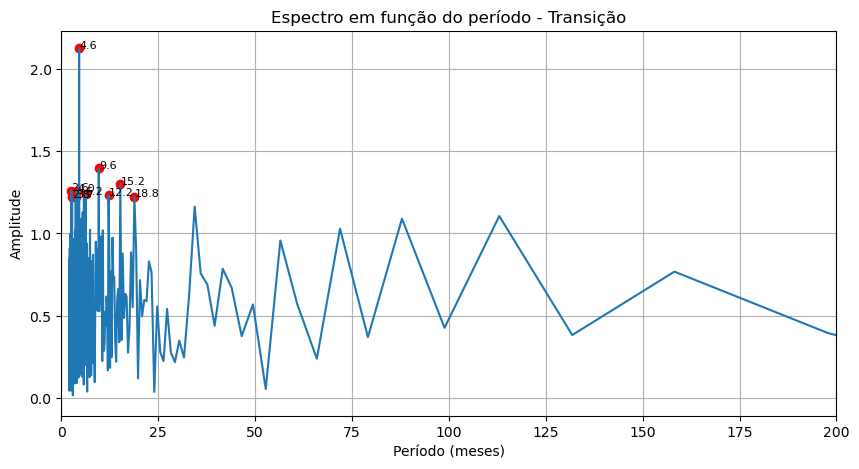

In [132]:
import matplotlib.pyplot as plt

# Quantos maiores picos deseja
top_n = 10

# Índices das maiores amplitudes
idx_top = np.argsort(amplitude_pos)[-top_n:][::-1]

print("Maiores amplitudes:\n")

for i in idx_top:
    print(f"Período: {periods_pos[i]:.2f} meses | Amplitude: {amplitude_pos[i]:.2f}")

# Magnitude da FFT (antes de remover, pra visualizar os ciclos)
amplitude = np.abs(fft_vals)

# Evitar divisão por zero
periods = np.where(freqs != 0, 1/freqs, np.inf)

# Pegar só frequências positivas
mask_pos = freqs > 0

periods_pos = periods[mask_pos]
amplitude_pos = amplitude[mask_pos]

# Plot
plt.figure(figsize=(10,5))
plt.plot(periods_pos, amplitude_pos)

# Destacar maiores picos
plt.scatter(periods_pos[idx_top],
            amplitude_pos[idx_top],
            color='red')

for i in idx_top:
    plt.text(periods_pos[i],
             amplitude_pos[i],
             f"{periods_pos[i]:.1f}",
             fontsize=8)

plt.xlabel("Período (meses)")
plt.ylabel("Amplitude")
plt.title("Espectro em função do período - Transição")
plt.xlim(0, 200)
plt.grid()
plt.savefig('CIclos Transição')
plt.show()

## Ciclos pra Bottom

In [135]:
janFUNDO = []
fevFUNDO= []
marFUNDO = []
aprFUNDO = []
mayFUNDO = []
junFUNDO = []
julFUNDO = []
augFUNDO = []
sepFUNDO= []
octoFUNDO = []
novFUNDO= []
dezFUNDO = []

for i in range(0, len(MHT_BOTTOM_PW) - 11, 12):
    janFUNDO.append(MHT_BOTTOM_PW[i])
    fevFUNDO.append(MHT_BOTTOM_PW[i+1])
    marFUNDO.append(MHT_BOTTOM_PW[i+2])
    aprFUNDO.append(MHT_BOTTOM_PW[i+3])
    mayFUNDO.append(MHT_BOTTOM_PW[i+4])
    junFUNDO.append(MHT_BOTTOM_PW[i+5])
    julFUNDO.append(MHT_BOTTOM_PW[i+6])
    augFUNDO.append(MHT_BOTTOM_PW[i+7])
    sepFUNDO.append(MHT_BOTTOM_PW[i+8])
    octoFUNDO.append(MHT_BOTTOM_PW[i+9])
    novFUNDO.append(MHT_BOTTOM_PW[i+10])
    dezFUNDO.append(MHT_BOTTOM_PW[i+11])

In [136]:
meses_dados_FUNDO = [janFUNDO, fevFUNDO, marFUNDO, aprFUNDO, mayFUNDO, junFUNDO, julFUNDO, augFUNDO, sepFUNDO, octoFUNDO, novFUNDO, dezFUNDO]
medias_FUNDO = [np.mean(m) for m in meses_dados_FUNDO]

In [137]:
medias_FUNDO

[np.float32(0.0011067477),
 np.float32(0.0009900496),
 np.float32(0.0010955998),
 np.float32(0.0009312054),
 np.float32(-0.0017775055),
 np.float32(-0.0030916217),
 np.float32(-0.0036631797),
 np.float32(-0.0018724395),
 np.float32(-0.0009971757),
 np.float32(9.232815e-05),
 np.float32(-0.00015603476),
 np.float32(-0.0004019079)]

In [139]:
serie_toda_fundo = medias_FUNDO * 66
serie_toda_fundo.pop()

np.float32(-0.0004019079)

In [140]:
MHT_FUNDO_SEM_ANUAL = []
for i in range (len(MHT_BOTTOM_PW)):
    MHT_FUNDO_SEM_ANUAL.append(MHT_BOTTOM_PW[i] - serie_toda_fundo[i])

In [141]:
import numpy as np
from scipy.fft import fft, ifft, fftfreq

# Supondo:
# MHT_total_em_PW -> array 1D
# t -> lista de datetime mensais

# Número de pontos
N = len(MHT_FUNDO_SEM_ANUAL)

# Intervalo de amostragem (mensal = 1 mês)
dt = 1  # unidade: mês

# FFT
fft_vals = fft(MHT_FUNDO_SEM_ANUAL)

# Frequências
freqs = fftfreq(N, d=dt)

# Frequências dos ciclos que queremos remover (em ciclos por mês)
f_12 = 1/12
f_6 = 1/6
f_3 = 1/3
f_780 = 1/780
f_min = 1 / 200

# Tolerância para pegar os bins corretos
tol = 1e-4

# Criar máscara para remover essas frequências (e simétricas negativas)
mask = (
    # ciclos específicos
    (np.abs(freqs - f_12) < tol) | (np.abs(freqs + f_12) < tol) |
    (np.abs(freqs - f_6) < tol)  | (np.abs(freqs + f_6) < tol)  |
    (np.abs(freqs - f_3) < tol)  | (np.abs(freqs + f_3) < tol)  |
    (np.abs(freqs - f_780) < tol)| (np.abs(freqs + f_780) < tol) |

    # 🔴 remover ciclos maiores que N/2 meses (baixa frequência)
    (np.abs(freqs) < f_min)
)

# Zerar essas componentes
fft_vals[mask] = 0

# Reconstruir sinal sem esses ciclos
MHT_filtrado = np.real(ifft(fft_vals))

Maiores amplitudes:

Período: 11.81 meses | Amplitude: 0.41
Período: 12.17 meses | Amplitude: 0.35
Período: 4.32 meses | Amplitude: 0.30
Período: 27.28 meses | Amplitude: 0.29
Período: 5.90 meses | Amplitude: 0.29
Período: 197.75 meses | Amplitude: 0.29
Período: 5.53 meses | Amplitude: 0.27
Período: 3.32 meses | Amplitude: 0.27
Período: 2.05 meses | Amplitude: 0.26
Período: 4.10 meses | Amplitude: 0.26


/tmp/ipykernel_4637/3875546573.py:18: RuntimeWarning: divide by zero encountered in divide
  periods = np.where(freqs != 0, 1/freqs, np.inf)


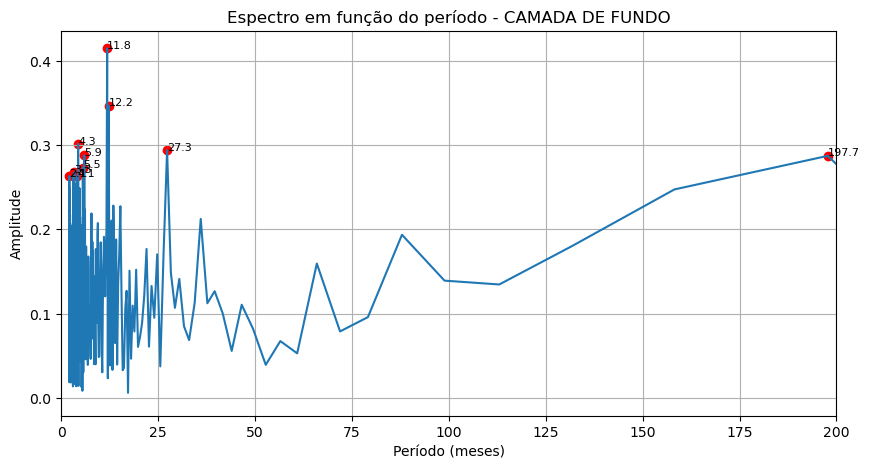

In [143]:
import matplotlib.pyplot as plt

# Quantos maiores picos deseja
top_n = 10

# Índices das maiores amplitudes
idx_top = np.argsort(amplitude_pos)[-top_n:][::-1]

print("Maiores amplitudes:\n")

for i in idx_top:
    print(f"Período: {periods_pos[i]:.2f} meses | Amplitude: {amplitude_pos[i]:.2f}")

# Magnitude da FFT (antes de remover, pra visualizar os ciclos)
amplitude = np.abs(fft_vals)

# Evitar divisão por zero
periods = np.where(freqs != 0, 1/freqs, np.inf)

# Pegar só frequências positivas
mask_pos = freqs > 0

periods_pos = periods[mask_pos]
amplitude_pos = amplitude[mask_pos]

# Plot
plt.figure(figsize=(10,5))
plt.plot(periods_pos, amplitude_pos)

# Destacar maiores picos
plt.scatter(periods_pos[idx_top],
            amplitude_pos[idx_top],
            color='red')

for i in idx_top:
    plt.text(periods_pos[i],
             amplitude_pos[i],
             f"{periods_pos[i]:.1f}",
             fontsize=8)

plt.xlabel("Período (meses)")
plt.ylabel("Amplitude")
plt.title("Espectro em função do período - CAMADA DE FUNDO")
plt.xlim(0, 200)
plt.grid()
plt.savefig('Ciclos Fundo')
plt.show()